# 11-8. 평균 통행시간을 포함한 셀 단위 기본모형 OLS

- 분석 단위: 공급구조가 유지된 126개 250m 격자
- 종속변수: 2025-11-06 종일 승차인원 − 2024-10-17 종일 승차인원
- 기준집단: GTX-A역 보행시간 60분 초과 격자
- 기본 독립변수: 보행시간 더미 2개, 건축물 수, 20~50대 인구, 경쟁 목적지 비율, 평균 버스 통행시간, IC 도로거리, 주거지역 비율
- 표준오차: HC3 이분산 강건 표준오차

In [1]:
# 프로젝트 루트(UROP) 자동 탐색 — 절대경로 없이 어느 컴퓨터에서도 동작
import sys
from pathlib import Path
UROP_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'config.py').is_file() and (p / 'code').is_dir())
for _d in [UROP_ROOT, *sorted(d for d in (UROP_ROOT / 'code').rglob('*') if d.is_dir() and d.name != '__pycache__')]:
    if str(_d) not in sys.path:
        sys.path.append(str(_d))

# 기본모형: 보행시간 더미 2개 + 지역특성 + 2024년 평균 광역버스 통행시간
from pathlib import Path
import numpy as np
import pandas as pd
import statsmodels.api as sm
from IPython.display import display

PROJECT = UROP_ROOT
PROCESSED = PROJECT / 'data' / 'processed' / 'gtx_a'
MODEL_PATH = PROCESSED / '18_새데이터_회귀분석_격자통합데이터.csv'
EXTRA_PATH = PROCESSED / '18-1_새데이터_추가피처_250m격자.csv'
LAND_USE_PATH = PROCESSED / '19_용도지역_면적비율_250m격자.csv'
ID = '셀 ID'

def read_csv(path):
    return pd.read_csv(path, encoding='utf-8-sig', low_memory=False)

model = read_csv(MODEL_PATH)
extra = read_csv(EXTRA_PATH)
land_use = read_csv(LAND_USE_PATH)
model[ID] = pd.to_numeric(model[ID], errors='coerce').astype('Int64')
extra[ID] = pd.to_numeric(extra[ID], errors='coerce').astype('Int64')
land_use[ID] = pd.to_numeric(land_use[ID], errors='coerce').astype('Int64')
model = model.merge(extra[[ID, 'bus_time_mean']], on=ID, how='left', validate='one_to_one')
model = model.merge(land_use[[ID, '주거지역 비율(%)']], on=ID, how='left', validate='one_to_one')
model['bus_time_mean'] = pd.to_numeric(model['bus_time_mean'], errors='coerce')

FEATURES = [
    'walk_20', 'walk_20_60', 'buildings', 'pop_20_50',
    'competing_share', 'bus_time_mean', 'ic_access', '주거지역 비율(%)'
]
LABELS = {
    'walk_20': 'GTX 보행 20분 이내',
    'walk_20_60': 'GTX 보행 20~60분',
    'buildings': '2024년 건축물 수',
    'pop_20_50': '2024년 20~50대 인구',
    'competing_share': 'GTX 경쟁 목적지 비율(%)',
    'bus_time_mean': '2024년 평균 버스 통행시간(분)',
    'ic_access': 'IC까지 도로거리(km)',
    '주거지역 비율(%)': '주거지역 비율(%)',
}

required = ['change_all'] + FEATURES
for column in required:
    model[column] = pd.to_numeric(model[column], errors='coerce')
sample = model.dropna(subset=required).copy()
if len(sample) != 126:
    print(f'주의: 전체 126개 중 통행시간 등 결측치를 제외한 {len(sample)}개 셀을 분석합니다.')

X = sm.add_constant(sample[FEATURES].astype(float), has_constant='add')
fit = sm.OLS(sample['change_all'].astype(float), X).fit(cov_type='HC3')

print('=' * 90)
print('기본모형_3구간더미_평균통행시간_주거지역비율포함')
print(fit.summary())

ci = fit.conf_int().loc[FEATURES]
result_table = pd.DataFrame({
    '변수': [LABELS[v] for v in FEATURES],
    '계수(명)': fit.params.loc[FEATURES].values,
    'HC3 표준오차': fit.bse.loc[FEATURES].values,
    'z값': fit.tvalues.loc[FEATURES].values,
    'p값': fit.pvalues.loc[FEATURES].values,
    '95% CI 하한': ci[0].values,
    '95% CI 상한': ci[1].values,
})
result_table['유의성'] = np.select(
    [result_table['p값'] < 0.01, result_table['p값'] < 0.05, result_table['p값'] < 0.10],
    ['***', '**', '*'], default=''
)
display(result_table.round(4))

model_table = pd.DataFrame([{
    '표본 수': int(fit.nobs),
    'R²': fit.rsquared,
    '수정 R²': fit.rsquared_adj,
    '모형 F값': float(fit.fvalue),
    '모형 p값': float(fit.f_pvalue),
    'AIC': fit.aic,
    'BIC': fit.bic,
}])
display(model_table.round(4))

기본모형_3구간더미_평균통행시간_주거지역비율포함
                            OLS Regression Results                            
Dep. Variable:             change_all   R-squared:                       0.210
Model:                            OLS   Adj. R-squared:                  0.156
Method:                 Least Squares   F-statistic:                     3.686
Date:                Fri, 09 Oct 2026   Prob (F-statistic):           0.000719
Time:                        12:03:54   Log-Likelihood:                -825.17
No. Observations:                 126   AIC:                             1668.
Df Residuals:                     117   BIC:                             1694.
Df Model:                           8                                         
Covariance Type:                  HC3                                         
                      coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------
const          

,변수,계수(명),HC3 표준오차,z값,p값,95% CI 하한,95% CI 상한,유의성
0,GTX 보행 20분 이내,-277.3240,73.8508,-3.7552,0.0002,-422.0690,-132.5791,***
1,GTX 보행 20~60분,-121.3614,42.3764,-2.8639,0.0042,-204.4176,-38.3051,***
2,2024년 건축물 수,0.7390,0.3410,2.1673,0.0302,0.0707,1.4074,**
3,2024년 20~50대 인구,-0.0525,0.0429,-1.2244,0.2208,-0.1365,0.0315,
4,GTX 경쟁 목적지 비율(%),-0.7680,0.6668,-1.1518,0.2494,-2.0748,0.5388,
5,2024년 평균 버스 통행시간(분),-0.6451,1.2090,-0.5336,0.5936,-3.0147,1.7244,
6,IC까지 도로거리(km),1.5867,3.8574,0.4113,0.6808,-5.9736,9.1470,
7,주거지역 비율(%),1.3249,0.8546,1.5504,0.1210,-0.3500,2.9998,


,표본 수,R²,수정 R²,모형 F값,모형 p값,AIC,BIC
0,126,0.2099,0.1559,3.6865,0.0007,1668.3386,1693.8651


# 비교모형 1: GTX역 보행시간을 분 단위 연속형으로 투입


In [21]:
# 비교모형 1: GTX역 보행시간을 분 단위 연속형으로 투입
CONT_FEATURES = [
    'walk_min', 'buildings', 'pop_20_50', 'competing_share',
    'bus_time_mean', 'ic_access', '주거지역 비율(%)'
]
CONT_LABELS = {**LABELS, 'walk_min': 'GTX역 보행시간(분)'}
continuous_sample = model.dropna(subset=['change_all'] + CONT_FEATURES).copy()
X_cont = sm.add_constant(continuous_sample[CONT_FEATURES].astype(float), has_constant='add')
fit_cont = sm.OLS(continuous_sample['change_all'].astype(float), X_cont).fit(cov_type='HC3')
print('=' * 90)
print('비교모형1_보행시간_연속형_평균통행시간포함')
print(fit_cont.summary())
ci_cont = fit_cont.conf_int().loc[CONT_FEATURES]
continuous_result = pd.DataFrame({
    '변수': [CONT_LABELS[v] for v in CONT_FEATURES],
    '계수(명)': fit_cont.params.loc[CONT_FEATURES].values,
    'HC3 표준오차': fit_cont.bse.loc[CONT_FEATURES].values,
    'z값': fit_cont.tvalues.loc[CONT_FEATURES].values,
    'p값': fit_cont.pvalues.loc[CONT_FEATURES].values,
    '95% CI 하한': ci_cont[0].values,
    '95% CI 상한': ci_cont[1].values,
})
display(continuous_result.round(4))
display(pd.DataFrame([{'표본 수': int(fit_cont.nobs), 'R²': fit_cont.rsquared, '수정 R²': fit_cont.rsquared_adj, '모형 F값': float(fit_cont.fvalue), '모형 p값': float(fit_cont.f_pvalue), 'AIC': fit_cont.aic, 'BIC': fit_cont.bic}]).round(4))

비교모형1_보행시간_연속형_평균통행시간포함
                            OLS Regression Results                            
Dep. Variable:             change_all   R-squared:                       0.187
Model:                            OLS   Adj. R-squared:                  0.139
Method:                 Least Squares   F-statistic:                     1.814
Date:                   목, 08 10 2026   Prob (F-statistic):             0.0908
Time:                        00:41:51   Log-Likelihood:                -826.94
No. Observations:                 126   AIC:                             1670.
Df Residuals:                     118   BIC:                             1693.
Df Model:                           7                                         
Covariance Type:                  HC3                                         
                      coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------
const            -

,변수,계수(명),HC3 표준오차,z값,p값,95% CI 하한,95% CI 상한
0,GTX역 보행시간(분),1.6521,0.6222,2.6553,0.0079,0.4326,2.8716
1,2024년 건축물 수,0.4145,0.3837,1.0804,0.2800,-0.3375,1.1665
2,2024년 20~50대 인구,-0.0477,0.0429,-1.1138,0.2654,-0.1317,0.0363
3,GTX 경쟁 목적지 비율(%),-0.8643,0.6985,-1.2373,0.2160,-2.2334,0.5048
4,2024년 평균 버스 통행시간(분),-0.5452,1.3199,-0.4131,0.6795,-3.1323,2.0418
5,IC까지 도로거리(km),0.3752,4.4651,0.0840,0.9330,-8.3763,9.1267
6,주거지역 비율(%),1.6626,0.9752,1.7049,0.0882,-0.2487,3.5740


,표본 수,R²,수정 R²,모형 F값,모형 p값,AIC,BIC
0,126,0.1874,0.1392,1.8139,0.0908,1669.8726,1692.5628


# 비교모형 2: 15분 이내 / 15~30분 / 30분 초과(기준집단)


In [22]:
# 비교모형 2: 15분 이내 / 15~30분 / 30분 초과(기준집단)
model['walk_15'] = (model['walk_min'] <= 15).astype(float)
model['walk_15_30'] = ((model['walk_min'] > 15) & (model['walk_min'] <= 30)).astype(float)
DUMMY1530_FEATURES = [
    'walk_15', 'walk_15_30', 'buildings', 'pop_20_50',
    'competing_share', 'bus_time_mean', 'ic_access', '주거지역 비율(%)'
]
DUMMY1530_LABELS = {
    **LABELS,
    'walk_15': 'GTX 보행 15분 이내',
    'walk_15_30': 'GTX 보행 15~30분',
}
dummy1530_sample = model.dropna(subset=['change_all'] + DUMMY1530_FEATURES).copy()
X_1530 = sm.add_constant(dummy1530_sample[DUMMY1530_FEATURES].astype(float), has_constant='add')
fit_1530 = sm.OLS(dummy1530_sample['change_all'].astype(float), X_1530).fit(cov_type='HC3')
print('구간별 셀 수')
display(pd.Series(np.select([model['walk_15'].eq(1), model['walk_15_30'].eq(1)], ['15분 이내', '15~30분'], default='30분 초과')).value_counts().reindex(['15분 이내', '15~30분', '30분 초과']).to_frame('셀 수'))
print('=' * 90)
print('비교모형2_15분_30분_구간더미_평균통행시간포함')
print(fit_1530.summary())
ci_1530 = fit_1530.conf_int().loc[DUMMY1530_FEATURES]
dummy1530_result = pd.DataFrame({
    '변수': [DUMMY1530_LABELS[v] for v in DUMMY1530_FEATURES],
    '계수(명)': fit_1530.params.loc[DUMMY1530_FEATURES].values,
    'HC3 표준오차': fit_1530.bse.loc[DUMMY1530_FEATURES].values,
    'z값': fit_1530.tvalues.loc[DUMMY1530_FEATURES].values,
    'p값': fit_1530.pvalues.loc[DUMMY1530_FEATURES].values,
    '95% CI 하한': ci_1530[0].values,
    '95% CI 상한': ci_1530[1].values,
})
display(dummy1530_result.round(4))
display(pd.DataFrame([{'표본 수': int(fit_1530.nobs), 'R²': fit_1530.rsquared, '수정 R²': fit_1530.rsquared_adj, '모형 F값': float(fit_1530.fvalue), '모형 p값': float(fit_1530.f_pvalue), 'AIC': fit_1530.aic, 'BIC': fit_1530.bic}]).round(4))

구간별 셀 수


,셀 수
15분 이내,3
15~30분,23
30분 초과,100


비교모형2_15분_30분_구간더미_평균통행시간포함
                            OLS Regression Results                            
Dep. Variable:             change_all   R-squared:                       0.290
Model:                            OLS   Adj. R-squared:                  0.241
Method:                 Least Squares   F-statistic:                     4.373
Date:                   목, 08 10 2026   Prob (F-statistic):           0.000121
Time:                        00:41:51   Log-Likelihood:                -818.43
No. Observations:                 126   AIC:                             1655.
Df Residuals:                     117   BIC:                             1680.
Df Model:                           8                                         
Covariance Type:                  HC3                                         
                      coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------
const         

,변수,계수(명),HC3 표준오차,z값,p값,95% CI 하한,95% CI 상한
0,GTX 보행 15분 이내,-501.8975,119.3598,-4.2049,0.0000,-735.8384,-267.9565
1,GTX 보행 15~30분,-149.4260,71.5372,-2.0888,0.0367,-289.6363,-9.2157
2,2024년 건축물 수,0.8511,0.3454,2.4643,0.0137,0.1742,1.5280
3,2024년 20~50대 인구,-0.0122,0.0432,-0.2828,0.7773,-0.0968,0.0724
4,GTX 경쟁 목적지 비율(%),-0.5908,0.5474,-1.0794,0.2804,-1.6637,0.4820
5,2024년 평균 버스 통행시간(분),-1.8960,1.2304,-1.5410,0.1233,-4.3076,0.5155
6,IC까지 도로거리(km),5.0417,3.2923,1.5314,0.1257,-1.4110,11.4944
7,주거지역 비율(%),0.3369,0.7741,0.4353,0.6634,-1.1802,1.8540


,표본 수,R²,수정 R²,모형 F값,모형 p값,AIC,BIC
0,126,0.29,0.2415,4.3726,0.0001,1654.8607,1680.3872


 ### 1. 보행시간 구간 × 경쟁 목적지 비율
  > GTX-A역에 가까우면서 경쟁 목적지 비율이 높은 지역일수록 광역버스 승차인원 변
  > 화량이 더 낮을 것이다(−).

In [23]:
# 상호작용모형: 보행시간 구간 × 경쟁 목적지 비율
from statsmodels.stats.outliers_influence import variance_inflation_factor

interaction_model = model.copy()
# 평균중심화: 0이 표본의 평균 경쟁 목적지 비율을 의미하도록 설정
interaction_model['comp_centered'] = (
    interaction_model['competing_share'] - interaction_model['competing_share'].mean()
)
interaction_model['walk15_x_comp'] = interaction_model['walk_15'] * interaction_model['comp_centered']
interaction_model['walk1530_x_comp'] = interaction_model['walk_15_30'] * interaction_model['comp_centered']

INTERACTION_FEATURES = [
    'walk_15', 'walk_15_30', 'comp_centered',
    'walk15_x_comp', 'walk1530_x_comp',
    'buildings', 'pop_20_50', 'bus_time_mean', 'ic_access', '주거지역 비율(%)'
]
INTERACTION_LABELS = {
    'walk_15': 'GTX 보행 15분 이내',
    'walk_15_30': 'GTX 보행 15~30분',
    'comp_centered': 'GTX 경쟁 목적지 비율(평균중심화)',
    'walk15_x_comp': '15분 이내 × 경쟁 목적지 비율',
    'walk1530_x_comp': '15~30분 × 경쟁 목적지 비율',
    'buildings': '2024년 건축물 수',
    'pop_20_50': '2024년 20~50대 인구',
    'bus_time_mean': '2024년 평균 버스 통행시간(분)',
    'ic_access': 'IC까지 도로거리(km)',
    '주거지역 비율(%)': '주거지역 비율(%)',
}
interaction_sample = interaction_model.dropna(subset=['change_all'] + INTERACTION_FEATURES).copy()
X_interaction = sm.add_constant(interaction_sample[INTERACTION_FEATURES].astype(float), has_constant='add')
fit_interaction = sm.OLS(interaction_sample['change_all'].astype(float), X_interaction).fit(cov_type='HC3')
print('=' * 90)
print('상호작용모형_보행시간구간×경쟁목적지비율')
print(fit_interaction.summary())
ci_interaction = fit_interaction.conf_int().loc[INTERACTION_FEATURES]
interaction_result = pd.DataFrame({
    '변수': [INTERACTION_LABELS[v] for v in INTERACTION_FEATURES],
    '계수(명)': fit_interaction.params.loc[INTERACTION_FEATURES].values,
    'HC3 표준오차': fit_interaction.bse.loc[INTERACTION_FEATURES].values,
    'z값': fit_interaction.tvalues.loc[INTERACTION_FEATURES].values,
    'p값': fit_interaction.pvalues.loc[INTERACTION_FEATURES].values,
    '95% CI 하한': ci_interaction[0].values,
    '95% CI 상한': ci_interaction[1].values,
})
display(interaction_result.round(4))

interaction_comparison = pd.DataFrame([
    {'모형': '15·30분 기본모형', '변수 수': len(DUMMY1530_FEATURES), 'R²': fit_1530.rsquared, '수정 R²': fit_1530.rsquared_adj, '모형 p값': fit_1530.f_pvalue, 'AIC': fit_1530.aic, 'BIC': fit_1530.bic},
    {'모형': '보행구간×경쟁목적지', '변수 수': len(INTERACTION_FEATURES), 'R²': fit_interaction.rsquared, '수정 R²': fit_interaction.rsquared_adj, '모형 p값': fit_interaction.f_pvalue, 'AIC': fit_interaction.aic, 'BIC': fit_interaction.bic},
])
display(interaction_comparison.round(4))

vif_table = pd.DataFrame({
    '변수': [INTERACTION_LABELS[v] for v in INTERACTION_FEATURES],
    'VIF': [variance_inflation_factor(X_interaction.to_numpy(), X_interaction.columns.get_loc(v)) for v in INTERACTION_FEATURES],
}).sort_values('VIF', ascending=False)
display(vif_table.round(3))

상호작용모형_보행시간구간×경쟁목적지비율
                            OLS Regression Results                            
Dep. Variable:             change_all   R-squared:                       0.297
Model:                            OLS   Adj. R-squared:                  0.242
Method:                 Least Squares   F-statistic:                     3.766
Date:                   목, 08 10 2026   Prob (F-statistic):           0.000346
Time:                        00:41:52   Log-Likelihood:                -817.82
No. Observations:                 126   AIC:                             1656.
Df Residuals:                     116   BIC:                             1684.
Df Model:                           9                                         
Covariance Type:                  HC3                                         
                      coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------
const             -4

c:\mini\envs\smartcity\lib\site-packages\statsmodels\base\model.py:1894: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 10, but rank is 9
  warnings.warn('covariance of constraints does not have full '


,변수,계수(명),HC3 표준오차,z값,p값,95% CI 하한,95% CI 상한
0,GTX 보행 15분 이내,-4.1815,1.0181,-4.1071,0.0000,-6.1769,-2.1860
1,GTX 보행 15~30분,-149.4388,72.2670,-2.0679,0.0387,-291.0795,-7.7981
2,GTX 경쟁 목적지 비율(평균중심화),-0.1996,0.4100,-0.4868,0.6264,-1.0032,0.6040
3,15분 이내 × 경쟁 목적지 비율,45.4597,11.0685,4.1071,0.0000,23.7659,67.1535
4,15~30분 × 경쟁 목적지 비율,-2.5332,4.1333,-0.6129,0.5400,-10.6342,5.5679
5,2024년 건축물 수,0.7958,0.3350,2.3752,0.0175,0.1391,1.4524
6,2024년 20~50대 인구,-0.0149,0.0437,-0.3403,0.7336,-0.1006,0.0708
7,2024년 평균 버스 통행시간(분),-1.6484,1.1571,-1.4246,0.1543,-3.9163,0.6195
8,IC까지 도로거리(km),3.7672,3.3667,1.1189,0.2632,-2.8315,10.3658
9,주거지역 비율(%),0.4022,0.7799,0.5158,0.6060,-1.1263,1.9307


,모형,변수 수,R²,수정 R²,모형 p값,AIC,BIC
0,15·30분 기본모형,8,0.2900,0.2415,0.0001,1654.8607,1680.3872
1,보행구간×경쟁목적지,10,0.2969,0.2424,0.0003,1655.6358,1683.9987


c:\mini\envs\smartcity\lib\site-packages\statsmodels\stats\outliers_influence.py:197: RuntimeWarning: divide by zero encountered in scalar divide
  vif = 1. / (1. - r_squared_i)


,변수,VIF
0,GTX 보행 15분 이내,inf
3,15분 이내 × 경쟁 목적지 비율,inf
9,주거지역 비율(%),1.879
6,2024년 20~50대 인구,1.861
2,GTX 경쟁 목적지 비율(평균중심화),1.364
8,IC까지 도로거리(km),1.229
4,15~30분 × 경쟁 목적지 비율,1.227
1,GTX 보행 15~30분,1.097
7,2024년 평균 버스 통행시간(분),1.078
5,2024년 건축물 수,1.068


# 상호작용모형: 기존 20·60분 보행구간 × 경쟁 목적지 비율


In [24]:
# 상호작용모형: 기존 20·60분 보행구간 × 경쟁 목적지 비율
interaction20_model = model.copy()
interaction20_model['comp_centered'] = (
    interaction20_model['competing_share'] - interaction20_model['competing_share'].mean()
)
interaction20_model['walk20_x_comp'] = interaction20_model['walk_20'] * interaction20_model['comp_centered']
interaction20_model['walk2060_x_comp'] = interaction20_model['walk_20_60'] * interaction20_model['comp_centered']
INTERACTION20_FEATURES = [
    'walk_20', 'walk_20_60', 'comp_centered',
    'walk20_x_comp', 'walk2060_x_comp',
    'buildings', 'pop_20_50', 'bus_time_mean', 'ic_access', '주거지역 비율(%)'
]
INTERACTION20_LABELS = {
    'walk_20': 'GTX 보행 20분 이내',
    'walk_20_60': 'GTX 보행 20~60분',
    'comp_centered': 'GTX 경쟁 목적지 비율(평균중심화)',
    'walk20_x_comp': '20분 이내 × 경쟁 목적지 비율',
    'walk2060_x_comp': '20~60분 × 경쟁 목적지 비율',
    'buildings': '2024년 건축물 수',
    'pop_20_50': '2024년 20~50대 인구',
    'bus_time_mean': '2024년 평균 버스 통행시간(분)',
    'ic_access': 'IC까지 도로거리(km)',
    '주거지역 비율(%)': '주거지역 비율(%)',
}
interaction20_sample = interaction20_model.dropna(subset=['change_all'] + INTERACTION20_FEATURES).copy()
X_interaction20 = sm.add_constant(interaction20_sample[INTERACTION20_FEATURES].astype(float), has_constant='add')
fit_interaction20 = sm.OLS(interaction20_sample['change_all'].astype(float), X_interaction20).fit(cov_type='HC3')
print('=' * 90)
print('상호작용모형_20·60분보행구간×경쟁목적지비율')
print(fit_interaction20.summary())
ci_interaction20 = fit_interaction20.conf_int().loc[INTERACTION20_FEATURES]
interaction20_result = pd.DataFrame({
    '변수': [INTERACTION20_LABELS[v] for v in INTERACTION20_FEATURES],
    '계수(명)': fit_interaction20.params.loc[INTERACTION20_FEATURES].values,
    'HC3 표준오차': fit_interaction20.bse.loc[INTERACTION20_FEATURES].values,
    'z값': fit_interaction20.tvalues.loc[INTERACTION20_FEATURES].values,
    'p값': fit_interaction20.pvalues.loc[INTERACTION20_FEATURES].values,
    '95% CI 하한': ci_interaction20[0].values,
    '95% CI 상한': ci_interaction20[1].values,
})
display(interaction20_result.round(4))
comparison20 = pd.DataFrame([
    {'모형': '20·60분 기본모형', 'R²': fit.rsquared, '수정 R²': fit.rsquared_adj, '모형 p값': fit.f_pvalue, 'AIC': fit.aic, 'BIC': fit.bic},
    {'모형': '20·60분×경쟁목적지', 'R²': fit_interaction20.rsquared, '수정 R²': fit_interaction20.rsquared_adj, '모형 p값': fit_interaction20.f_pvalue, 'AIC': fit_interaction20.aic, 'BIC': fit_interaction20.bic},
])
display(comparison20.round(4))
vif20 = pd.DataFrame({
    '변수': [INTERACTION20_LABELS[v] for v in INTERACTION20_FEATURES],
    'VIF': [variance_inflation_factor(X_interaction20.to_numpy(), X_interaction20.columns.get_loc(v)) for v in INTERACTION20_FEATURES],
}).sort_values('VIF', ascending=False)
display(vif20.round(3))

상호작용모형_20·60분보행구간×경쟁목적지비율
                            OLS Regression Results                            
Dep. Variable:             change_all   R-squared:                       0.242
Model:                            OLS   Adj. R-squared:                  0.176
Method:                 Least Squares   F-statistic:                     2.791
Date:                   목, 08 10 2026   Prob (F-statistic):            0.00397
Time:                        00:41:52   Log-Likelihood:                -822.52
No. Observations:                 126   AIC:                             1667.
Df Residuals:                     115   BIC:                             1698.
Df Model:                          10                                         
Covariance Type:                  HC3                                         
                      coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------
const           

,변수,계수(명),HC3 표준오차,z값,p값,95% CI 하한,95% CI 상한
0,GTX 보행 20분 이내,-278.7646,99.2884,-2.8076,0.0050,-473.3663,-84.1629
1,GTX 보행 20~60분,-137.2960,46.9816,-2.9223,0.0035,-229.3783,-45.2137
2,GTX 경쟁 목적지 비율(평균중심화),0.0520,0.3780,0.1375,0.8907,-0.6889,0.7928
3,20분 이내 × 경쟁 목적지 비율,1.7293,9.4474,0.1831,0.8548,-16.7872,20.2459
4,20~60분 × 경쟁 목적지 비율,-4.2177,1.9967,-2.1123,0.0347,-8.1313,-0.3042
5,2024년 건축물 수,0.7534,0.3518,2.1416,0.0322,0.0639,1.4429
6,2024년 20~50대 인구,-0.0509,0.0417,-1.2210,0.2221,-0.1325,0.0308
7,2024년 평균 버스 통행시간(분),-0.6491,1.0308,-0.6297,0.5289,-2.6694,1.3712
8,IC까지 도로거리(km),-0.7538,3.7545,-0.2008,0.8409,-8.1124,6.6049
9,주거지역 비율(%),1.4305,0.8767,1.6317,0.1027,-0.2878,3.1488


,모형,R²,수정 R²,모형 p값,AIC,BIC
0,20·60분 기본모형,0.2099,0.1559,0.0007,1668.3386,1693.8651
1,20·60분×경쟁목적지,0.2424,0.1765,0.0040,1667.0469,1698.2460


,변수,VIF
9,주거지역 비율(%),2.087
1,GTX 보행 20~60분,1.897
6,2024년 20~50대 인구,1.745
2,GTX 경쟁 목적지 비율(평균중심화),1.631
8,IC까지 도로거리(km),1.455
4,20~60분 × 경쟁 목적지 비율,1.425
0,GTX 보행 20분 이내,1.388
3,20분 이내 × 경쟁 목적지 비율,1.154
7,2024년 평균 버스 통행시간(분),1.114
5,2024년 건축물 수,1.077


## 10. 용도지역 면적비율 튜닝

먼저 `processing/11_독립변수_용도지역_250m격자.py`를 실행하여 VWorld API 키를 입력한다. 키는 파일에 저장되지 않는다. 건축물 수를 유지하면서 주거지역 비율을 기본모형에 추가한 경우를 비교한다.

In [25]:
LAND_USE_PATH = PROCESSED / '19_용도지역_면적비율_250m격자.csv'
if not LAND_USE_PATH.exists():
    raise FileNotFoundError('먼저 processing/11_독립변수_용도지역_250m격자.py를 실행하세요.')

land_use = read_csv(LAND_USE_PATH)
land_use[ID] = pd.to_numeric(land_use[ID], errors='coerce').astype('Int64')
zone_columns = ['주거지역 비율(%)', '상업지역 비율(%)', '공업지역 비율(%)', '녹지지역 비율(%)', '비도시지역 비율(%)']
for column in zone_columns:
    land_use[column] = pd.to_numeric(land_use[column], errors='coerce')

# 주거지역 비율은 위 기본모형에서 이미 결합했으므로 나머지 용도지역 변수만 추가한다.
additional_zone_columns = [c for c in zone_columns if c != '주거지역 비율(%)']
model_zone = model.merge(land_use[[ID] + additional_zone_columns], on=ID, how='left', validate='one_to_one')
base_with_time = FEATURES.copy()
zone_specs = {'기본모형': base_with_time}
common_zone = model_zone.dropna(subset=['change_all'] + sorted(set(sum(zone_specs.values(), [])))).copy()
zone_fits = {}
zone_comparison = []
for name, features in zone_specs.items():
    X_zone = sm.add_constant(common_zone[features].astype(float), has_constant='add')
    fit_zone = sm.OLS(common_zone['change_all'], X_zone).fit(cov_type='HC3')
    zone_fits[name] = fit_zone
    zone_comparison.append({
        '모형': name, '표본 수': int(fit_zone.nobs), 'R²': fit_zone.rsquared,
        '수정 R²': fit_zone.rsquared_adj, '모형 p값': fit_zone.f_pvalue,
        'AIC': fit_zone.aic, 'BIC': fit_zone.bic,
        '주거지역 비율 계수': fit_zone.params.get('주거지역 비율(%)', np.nan),
        '주거지역 비율 p값': fit_zone.pvalues.get('주거지역 비율(%)', np.nan),
    })
display(pd.DataFrame(zone_comparison).round(4))

for name, fit_zone in zone_fits.items():
    print('\n' + '=' * 90)
    print(name)
    print(fit_zone.summary())


,모형,표본 수,R²,수정 R²,모형 p값,AIC,BIC,주거지역 비율 계수,주거지역 비율 p값
0,기본모형,126,0.2099,0.1559,0.0007,1668.3386,1693.8651,1.3249,0.121



기본모형
                            OLS Regression Results                            
Dep. Variable:             change_all   R-squared:                       0.210
Model:                            OLS   Adj. R-squared:                  0.156
Method:                 Least Squares   F-statistic:                     3.686
Date:                   목, 08 10 2026   Prob (F-statistic):           0.000719
Time:                        00:41:52   Log-Likelihood:                -825.17
No. Observations:                 126   AIC:                             1668.
Df Residuals:                     117   BIC:                             1694.
Df Model:                           8                                         
Covariance Type:                  HC3                                         
                      coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------
const             -45.5986     54.24

## 10-1. 비도시지역 비율 추가 모형

가설: 비도시지역 비율이 높을수록 GTX 접근성이 낮아 광역버스 수요가 유지되므로, GTX-A 개통 후 광역버스 승차인원 변화량이 높을 것이다(+).

In [26]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

NONURBAN = '비도시지역 비율(%)'
nonurban_features = base_with_time + [NONURBAN]
nonurban_sample = model_zone.dropna(subset=['change_all'] + nonurban_features).copy()
X_nonurban = sm.add_constant(nonurban_sample[nonurban_features].astype(float), has_constant='add')
fit_nonurban = sm.OLS(nonurban_sample['change_all'].astype(float), X_nonurban).fit(cov_type='HC3')

print('=' * 90)
print('비도시지역비율_추가모형')
print(fit_nonurban.summary())

nonurban_comparison = pd.DataFrame([
    {'모형': '기본모형', '표본 수': int(zone_fits['기본모형'].nobs), 'R²': zone_fits['기본모형'].rsquared, '수정 R²': zone_fits['기본모형'].rsquared_adj, '모형 p값': zone_fits['기본모형'].f_pvalue, 'AIC': zone_fits['기본모형'].aic, 'BIC': zone_fits['기본모형'].bic},
    {'모형': '비도시지역비율_추가', '표본 수': int(fit_nonurban.nobs), 'R²': fit_nonurban.rsquared, '수정 R²': fit_nonurban.rsquared_adj, '모형 p값': fit_nonurban.f_pvalue, 'AIC': fit_nonurban.aic, 'BIC': fit_nonurban.bic},
])
display(nonurban_comparison.round(4))

nonurban_result = pd.DataFrame({
    '변수': nonurban_features,
    '계수(명)': fit_nonurban.params.loc[nonurban_features],
    'HC3 표준오차': fit_nonurban.bse.loc[nonurban_features],
    'p값': fit_nonurban.pvalues.loc[nonurban_features],
    '95% CI 하한': fit_nonurban.conf_int().loc[nonurban_features, 0],
    '95% CI 상한': fit_nonurban.conf_int().loc[nonurban_features, 1],
}).reset_index(drop=True)
display(nonurban_result.round(4))

vif_nonurban = pd.DataFrame({
    '변수': nonurban_features,
    'VIF': [variance_inflation_factor(X_nonurban.to_numpy(), X_nonurban.columns.get_loc(v)) for v in nonurban_features],
}).sort_values('VIF', ascending=False)
display(vif_nonurban.round(3))


비도시지역비율_추가모형
                            OLS Regression Results                            
Dep. Variable:             change_all   R-squared:                       0.231
Model:                            OLS   Adj. R-squared:                  0.171
Method:                 Least Squares   F-statistic:                     3.211
Date:                   목, 08 10 2026   Prob (F-statistic):            0.00165
Time:                        00:41:52   Log-Likelihood:                -823.46
No. Observations:                 126   AIC:                             1667.
Df Residuals:                     116   BIC:                             1695.
Df Model:                           9                                         
Covariance Type:                  HC3                                         
                      coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------
const             -93.7478   

,모형,표본 수,R²,수정 R²,모형 p값,AIC,BIC
0,기본모형,126,0.2099,0.1559,0.0007,1668.3386,1693.8651
1,비도시지역비율_추가,126,0.2310,0.1714,0.0017,1666.9204,1695.2832


,변수,계수(명),HC3 표준오차,p값,95% CI 하한,95% CI 상한
0,walk_20,-249.5207,72.1102,0.0005,-390.8542,-108.1873
1,walk_20_60,-105.9334,34.4530,0.0021,-173.4601,-38.4067
2,buildings,0.6179,0.3600,0.0861,-0.0877,1.3234
3,pop_20_50,-0.0545,0.0431,0.2060,-0.1390,0.0300
4,competing_share,-0.4924,0.6719,0.4636,-1.8094,0.8245
5,bus_time_mean,-1.0938,1.4812,0.4603,-3.9970,1.8094
6,ic_access,2.7025,4.3312,0.5327,-5.7865,11.1915
7,주거지역 비율(%),1.9093,1.2160,0.1164,-0.4739,4.2926
8,비도시지역 비율(%),1.0960,0.8012,0.1713,-0.4743,2.6664


,변수,VIF
7,주거지역 비율(%),2.681
8,비도시지역 비율(%),1.926
1,walk_20_60,1.895
3,pop_20_50,1.745
0,walk_20,1.449
6,ic_access,1.407
4,competing_share,1.162
5,bus_time_mean,1.118
2,buildings,1.088


## 11. 상호작용항 튜닝

- 보행시간 구간 × 버스 통행시간: GTX역에 가까우면서 기존 버스 통행시간이 길수록 승차인원 변화량이 낮을 것(−)
- 보행시간 구간 × 주거지역 비율: GTX역에 가까우면서 주거지역 비율이 높을수록 승차인원 변화량이 낮을 것(−)
- 보행시간 구간 × 경쟁 목적지 비율: GTX역에 가까우면서 경쟁 목적지 비율이 높을수록 승차인원 변화량이 낮을 것(−)

In [27]:
# 세 상호작용 모형을 한 셀에서 각각 추정한다.
interaction_sample = model_zone.dropna(
    subset=['change_all'] + base_with_time + ['주거지역 비율(%)']
).copy()

# 평균 중심화: 주효과 해석을 안정적으로 만들고 불필요한 다중공선성을 줄인다.
interaction_sample['bus_time_c'] = interaction_sample['bus_time_mean'] - interaction_sample['bus_time_mean'].mean()
interaction_sample['residential_c'] = interaction_sample['주거지역 비율(%)'] - interaction_sample['주거지역 비율(%)'].mean()
interaction_sample['competing_c'] = interaction_sample['competing_share'] - interaction_sample['competing_share'].mean()

interaction_sample['walk20_x_bus_time'] = interaction_sample['walk_20'] * interaction_sample['bus_time_c']
interaction_sample['walk20_60_x_bus_time'] = interaction_sample['walk_20_60'] * interaction_sample['bus_time_c']
interaction_sample['walk20_x_residential'] = interaction_sample['walk_20'] * interaction_sample['residential_c']
interaction_sample['walk20_60_x_residential'] = interaction_sample['walk_20_60'] * interaction_sample['residential_c']
interaction_sample['walk20_x_competing'] = interaction_sample['walk_20'] * interaction_sample['competing_c']
interaction_sample['walk20_60_x_competing'] = interaction_sample['walk_20_60'] * interaction_sample['competing_c']

common_main = [
    'walk_20', 'walk_20_60', 'buildings', 'pop_20_50',
    'competing_c', 'bus_time_c', 'ic_access', 'residential_c'
]
interaction_specs = {
    '보행구간×버스통행시간': common_main + ['walk20_x_bus_time', 'walk20_60_x_bus_time'],
    '보행구간×주거지역비율': common_main + ['walk20_x_residential', 'walk20_60_x_residential'],
    '보행구간×경쟁목적지비율': common_main + ['walk20_x_competing', 'walk20_60_x_competing'],
}
interaction_terms = {
    '보행구간×버스통행시간': ['walk20_x_bus_time', 'walk20_60_x_bus_time'],
    '보행구간×주거지역비율': ['walk20_x_residential', 'walk20_60_x_residential'],
    '보행구간×경쟁목적지비율': ['walk20_x_competing', 'walk20_60_x_competing'],
}

interaction_fits = {}
interaction_comparison = []
interaction_results = []
for model_name, features in interaction_specs.items():
    X_inter = sm.add_constant(interaction_sample[features].astype(float), has_constant='add')
    fitted = sm.OLS(interaction_sample['change_all'].astype(float), X_inter).fit(cov_type='HC3')
    interaction_fits[model_name] = fitted
    interaction_comparison.append({
        '모형': model_name, '표본 수': int(fitted.nobs), 'R²': fitted.rsquared,
        '수정 R²': fitted.rsquared_adj, '모형 F값': fitted.fvalue,
        '모형 p값': fitted.f_pvalue, 'AIC': fitted.aic, 'BIC': fitted.bic,
    })
    for term in interaction_terms[model_name]:
        interaction_results.append({
            '모형': model_name, '상호작용항': term, '계수(명)': fitted.params[term],
            'HC3 표준오차': fitted.bse[term], 'z값': fitted.tvalues[term],
            'p값': fitted.pvalues[term],
            '95% CI 하한': fitted.conf_int().loc[term, 0],
            '95% CI 상한': fitted.conf_int().loc[term, 1],
        })

print('===== 상호작용 모형 비교 =====')
display(pd.DataFrame(interaction_comparison).round(4))
print('===== 상호작용항 결과 =====')
display(pd.DataFrame(interaction_results).round(4))

for model_name, fitted in interaction_fits.items():
    print('\n' + '=' * 100)
    print(model_name)
    print(fitted.summary())


===== 상호작용 모형 비교 =====


,모형,표본 수,R²,수정 R²,모형 F값,모형 p값,AIC,BIC
0,보행구간×버스통행시간,126,0.2121,0.1436,2.9296,0.0026,1671.9785,1703.1776
1,보행구간×주거지역비율,126,0.2413,0.1753,3.2103,0.0011,1667.2307,1698.4298
2,보행구간×경쟁목적지비율,126,0.2424,0.1765,2.7906,0.0040,1667.0469,1698.2460


===== 상호작용항 결과 =====


,모형,상호작용항,계수(명),HC3 표준오차,z값,p값,95% CI 하한,95% CI 상한
0,보행구간×버스통행시간,walk20_x_bus_time,10.6022,33.1362,0.3200,0.7490,-54.3437,75.5480
1,보행구간×버스통행시간,walk20_60_x_bus_time,1.2304,2.1650,0.5683,0.5698,-3.0130,5.4738
2,보행구간×주거지역비율,walk20_x_residential,2.7536,3.1285,0.8802,0.3788,-3.3782,8.8854
3,보행구간×주거지역비율,walk20_60_x_residential,1.6762,1.4002,1.1971,0.2313,-1.0681,4.4204
4,보행구간×경쟁목적지비율,walk20_x_competing,1.7293,9.4474,0.1831,0.8548,-16.7872,20.2459
5,보행구간×경쟁목적지비율,walk20_60_x_competing,-4.2177,1.9967,-2.1123,0.0347,-8.1313,-0.3042



보행구간×버스통행시간
                            OLS Regression Results                            
Dep. Variable:             change_all   R-squared:                       0.212
Model:                            OLS   Adj. R-squared:                  0.144
Method:                 Least Squares   F-statistic:                     2.930
Date:                   목, 08 10 2026   Prob (F-statistic):            0.00262
Time:                        00:41:52   Log-Likelihood:                -824.99
No. Observations:                 126   AIC:                             1672.
Df Residuals:                     115   BIC:                             1703.
Df Model:                          10                                         
Covariance Type:                  HC3                                         
                           coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------
const              

## 12. 2024년 평균 이동거리 추가 모형

가설: 2024년 광역버스 이용거리가 길수록 GTX 전환 유인이 커져 GTX-A 개통 후 광역버스 승차인원 변화량이 낮을 것이다(−).

In [28]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

DISTANCE_PATH = PROCESSED / '21_광역버스이동거리_2024_종일_250m격자.csv'
DISTANCE = '2024년 승객가중 평균 이동거리(km)'
distance_data = read_csv(DISTANCE_PATH)
distance_data[ID] = pd.to_numeric(distance_data[ID], errors='coerce').astype('Int64')
distance_data[DISTANCE] = pd.to_numeric(distance_data[DISTANCE], errors='coerce')
model_distance = model.merge(
    distance_data[[ID, DISTANCE]], on=ID, how='left', validate='one_to_one'
)
distance_features = FEATURES + [DISTANCE]
distance_sample = model_distance.dropna(subset=['change_all'] + distance_features).copy()
X_distance = sm.add_constant(distance_sample[distance_features].astype(float), has_constant='add')
fit_distance = sm.OLS(
    distance_sample['change_all'].astype(float), X_distance
).fit(cov_type='HC3')

print('=' * 90)
print('기본모형_2024평균이동거리추가')
print(fit_distance.summary())

distance_comparison = pd.DataFrame([
    {'모형': '기본모형', '표본 수': int(fit.nobs), 'R²': fit.rsquared, '수정 R²': fit.rsquared_adj, '모형 F값': fit.fvalue, '모형 p값': fit.f_pvalue, 'AIC': fit.aic, 'BIC': fit.bic},
    {'모형': '평균이동거리_추가', '표본 수': int(fit_distance.nobs), 'R²': fit_distance.rsquared, '수정 R²': fit_distance.rsquared_adj, '모형 F값': fit_distance.fvalue, '모형 p값': fit_distance.f_pvalue, 'AIC': fit_distance.aic, 'BIC': fit_distance.bic},
])
display(distance_comparison.round(4))

distance_result = pd.DataFrame({
    '변수': distance_features,
    '계수(명)': fit_distance.params.loc[distance_features],
    'HC3 표준오차': fit_distance.bse.loc[distance_features],
    'z값': fit_distance.tvalues.loc[distance_features],
    'p값': fit_distance.pvalues.loc[distance_features],
    '95% CI 하한': fit_distance.conf_int().loc[distance_features, 0],
    '95% CI 상한': fit_distance.conf_int().loc[distance_features, 1],
}).reset_index(drop=True)
display(distance_result.round(4))

vif_distance = pd.DataFrame({
    '변수': distance_features,
    'VIF': [
        variance_inflation_factor(X_distance.to_numpy(), X_distance.columns.get_loc(variable))
        for variable in distance_features
    ],
}).sort_values('VIF', ascending=False)
print('===== 다중공선성(VIF) =====')
display(vif_distance.round(3))


기본모형_2024평균이동거리추가
                            OLS Regression Results                            
Dep. Variable:             change_all   R-squared:                       0.211
Model:                            OLS   Adj. R-squared:                  0.150
Method:                 Least Squares   F-statistic:                     3.318
Date:                   목, 08 10 2026   Prob (F-statistic):            0.00122
Time:                        00:41:52   Log-Likelihood:                -825.05
No. Observations:                 126   AIC:                             1670.
Df Residuals:                     116   BIC:                             1698.
Df Model:                           9                                         
Covariance Type:                  HC3                                         
                             coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------
const     

,모형,표본 수,R²,수정 R²,모형 F값,모형 p값,AIC,BIC
0,기본모형,126,0.2099,0.1559,3.6865,0.0007,1668.3386,1693.8651
1,평균이동거리_추가,126,0.2113,0.1502,3.3176,0.0012,1670.1046,1698.4674


,변수,계수(명),HC3 표준오차,z값,p값,95% CI 하한,95% CI 상한
0,walk_20,-276.7163,73.4552,-3.7671,0.0002,-420.6859,-132.7467
1,walk_20_60,-117.5255,42.6746,-2.7540,0.0059,-201.1663,-33.8848
2,buildings,0.7936,0.3679,2.1570,0.0310,0.0725,1.5148
3,pop_20_50,-0.0502,0.0429,-1.1698,0.2421,-0.1343,0.0339
4,competing_share,-0.6421,0.6964,-0.9220,0.3565,-2.0070,0.7228
5,bus_time_mean,-0.9251,1.4131,-0.6547,0.5127,-3.6946,1.8445
6,ic_access,1.0715,3.6533,0.2933,0.7693,-6.0888,8.2318
7,주거지역 비율(%),1.3080,0.8520,1.5352,0.1247,-0.3619,2.9778
8,2024년 승객가중 평균 이동거리(km),0.8556,1.3321,0.6423,0.5207,-1.7553,3.4666


===== 다중공선성(VIF) =====


,변수,VIF
7,주거지역 비율(%),2.015
1,walk_20_60,1.887
3,pop_20_50,1.773
6,ic_access,1.430
0,walk_20,1.369
8,2024년 승객가중 평균 이동거리(km),1.367
4,competing_share,1.237
5,bus_time_mean,1.216
2,buildings,1.118


## 13. 2024년 출근시간 승차인원 추가 모형

가설: 2024년 출근시간 승차인원이 많을수록 GTX로 전환할 통근수요가 많아 GTX-A 개통 후 광역버스 승차인원 변화량이 낮을 것이다(−). 출근시간은 06:00~09:59로 정의한다.

In [29]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

MORNING_PATH = PROCESSED / '22_출근시간승차비율_2024_종일_250m격자.csv'
MORNING_COUNT = '2024년 출근시간 승차인원(06~09시)'
morning_data = read_csv(MORNING_PATH)
morning_data[ID] = pd.to_numeric(morning_data[ID], errors='coerce').astype('Int64')
morning_data[MORNING_COUNT] = pd.to_numeric(morning_data[MORNING_COUNT], errors='coerce')
model_morning = model.merge(
    morning_data[[ID, MORNING_COUNT]], on=ID, how='left', validate='one_to_one'
)
morning_features = FEATURES + [MORNING_COUNT]
morning_sample = model_morning.dropna(subset=['change_all'] + morning_features).copy()
X_morning = sm.add_constant(morning_sample[morning_features].astype(float), has_constant='add')
fit_morning = sm.OLS(
    morning_sample['change_all'].astype(float), X_morning
).fit(cov_type='HC3')

print('=' * 90)
print('기본모형_2024출근시간승차인원추가')
print(fit_morning.summary())

morning_comparison = pd.DataFrame([
    {'모형': '기본모형', '표본 수': int(fit.nobs), 'R²': fit.rsquared, '수정 R²': fit.rsquared_adj, '모형 F값': fit.fvalue, '모형 p값': fit.f_pvalue, 'AIC': fit.aic, 'BIC': fit.bic},
    {'모형': '출근시간승차인원_추가', '표본 수': int(fit_morning.nobs), 'R²': fit_morning.rsquared, '수정 R²': fit_morning.rsquared_adj, '모형 F값': fit_morning.fvalue, '모형 p값': fit_morning.f_pvalue, 'AIC': fit_morning.aic, 'BIC': fit_morning.bic},
])
display(morning_comparison.round(4))

morning_result = pd.DataFrame({
    '변수': morning_features,
    '계수(명)': fit_morning.params.loc[morning_features],
    'HC3 표준오차': fit_morning.bse.loc[morning_features],
    'z값': fit_morning.tvalues.loc[morning_features],
    'p값': fit_morning.pvalues.loc[morning_features],
    '95% CI 하한': fit_morning.conf_int().loc[morning_features, 0],
    '95% CI 상한': fit_morning.conf_int().loc[morning_features, 1],
}).reset_index(drop=True)
display(morning_result.round(4))

vif_morning = pd.DataFrame({
    '변수': morning_features,
    'VIF': [
        variance_inflation_factor(X_morning.to_numpy(), X_morning.columns.get_loc(variable))
        for variable in morning_features
    ],
}).sort_values('VIF', ascending=False)
print('===== 다중공선성(VIF) =====')
display(vif_morning.round(3))


기본모형_2024출근시간승차인원추가
                            OLS Regression Results                            
Dep. Variable:             change_all   R-squared:                       0.870
Model:                            OLS   Adj. R-squared:                  0.860
Method:                 Least Squares   F-statistic:                     22.25
Date:                   목, 08 10 2026   Prob (F-statistic):           1.66e-21
Time:                        00:41:52   Log-Likelihood:                -711.44
No. Observations:                 126   AIC:                             1443.
Df Residuals:                     116   BIC:                             1471.
Df Model:                           9                                         
Covariance Type:                  HC3                                         
                              coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------
const 

,모형,표본 수,R²,수정 R²,모형 F값,모형 p값,AIC,BIC
0,기본모형,126,0.2099,0.1559,3.6865,0.0007,1668.3386,1693.8651
1,출근시간승차인원_추가,126,0.8701,0.8600,22.2529,0.0000,1442.8807,1471.2435


,변수,계수(명),HC3 표준오차,z값,p값,95% CI 하한,95% CI 상한
0,walk_20,-27.1016,81.8111,-0.3313,0.7404,-187.4483,133.2452
1,walk_20_60,-6.9215,13.1311,-0.5271,0.5981,-32.6581,18.8150
2,buildings,0.1295,0.2522,0.5135,0.6076,-0.3649,0.6239
3,pop_20_50,0.0172,0.0193,0.8931,0.3718,-0.0206,0.0551
4,competing_share,-0.0951,0.1745,-0.5452,0.5856,-0.4371,0.2469
5,bus_time_mean,-0.0857,0.3196,-0.2680,0.7887,-0.7121,0.5408
6,ic_access,4.1474,1.8937,2.1900,0.0285,0.4357,7.8590
7,주거지역 비율(%),0.3477,0.3398,1.0232,0.3062,-0.3183,1.0138
8,2024년 출근시간 승차인원(06~09시),-1.6735,0.2314,-7.2320,0.0000,-2.1271,-1.2200


===== 다중공선성(VIF) =====


,변수,VIF
7,주거지역 비율(%),2.067
1,walk_20_60,1.954
3,pop_20_50,1.804
0,walk_20,1.578
6,ic_access,1.397
8,2024년 출근시간 승차인원(06~09시),1.262
4,competing_share,1.131
5,bus_time_mean,1.098
2,buildings,1.085


## 14. 연도별 종일·출근시간 승차인원 비교

공급구조가 유지된 126개 격자의 전체 승차인원과 06~09시 출근시간 승차인원을 비교한다.

,구분,2024년,2025년
0,종일 전체,17894.0,5585.0
1,출근시간(06~09시),7809.0,2322.0


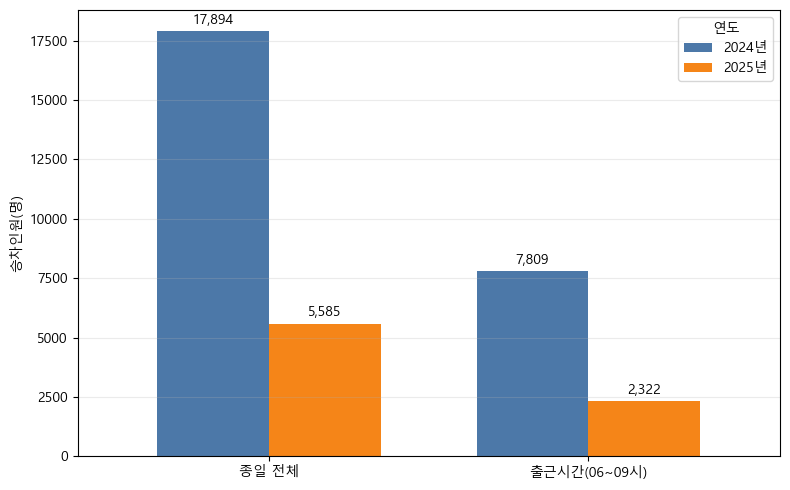

In [30]:
# 126개 격자의 연도별 종일·출근시간 승차인원 막대그래프
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

TIME_BAND_PATH = PROCESSED / '18-2_새데이터_시간대별_승차인원_셀.csv'
time_band = read_csv(TIME_BAND_PATH)
time_band[ID] = pd.to_numeric(time_band[ID], errors='coerce').astype('Int64')
morning_counts = time_band[time_band['시간대'].eq('출근')].copy()
if model[ID].nunique() != 126 or morning_counts[ID].nunique() != 126:
    raise ValueError(f'격자 수 확인 필요: 종일={model[ID].nunique()}, 출근={morning_counts[ID].nunique()}')

chart_data = pd.DataFrame({
    '구분': ['종일 전체', '출근시간(06~09시)'],
    '2024년': [model['board_2024_all'].sum(), morning_counts['board_2024'].sum()],
    '2025년': [model['board_2025_all'].sum(), morning_counts['board_2025'].sum()],
})
display(chart_data)

font_path = Path(r'C:\\Windows\\Fonts\\malgun.ttf')
if font_path.exists():
    fm.fontManager.addfont(str(font_path))
    plt.rcParams['font.family'] = fm.FontProperties(fname=str(font_path)).get_name()
plt.rcParams['axes.unicode_minus'] = False
ax = chart_data.set_index('구분')[['2024년', '2025년']].plot(
    kind='bar', figsize=(8, 5), color=['#4C78A8', '#F58518'], width=0.7
)
ax.set_xlabel('')
ax.set_ylabel('승차인원(명)')
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
ax.legend(title='연도')
for container in ax.containers:
    ax.bar_label(container, fmt='{:,.0f}', padding=3)
ax.grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.show()


## 15. 출근시간 승차변화량 요인 분석

종속변수와 교통카드 기반 독립변수를 모두 06~09시 기준으로 통일한다. 2024년 출근시간 승차가 없어 통행시간·통행거리·경쟁 목적지 비율을 계산할 수 없는 셀은 회귀 표본에서 제외한다.

In [31]:
# 출근시간(06~09시) 승차변화량 OLS: 시간 기준을 맞춘 피처 사용
MORNING_FEATURE_PATH = PROCESSED / '23_출근시간_분석피처_2024_250m격자.csv'
morning_feature = read_csv(MORNING_FEATURE_PATH)
morning_feature[ID] = pd.to_numeric(morning_feature[ID], errors='coerce').astype('Int64')

morning_model = model.merge(
    morning_counts[[ID, 'board_2024', 'board_2025', 'change']],
    on=ID, how='left', validate='one_to_one'
).merge(morning_feature, on=ID, how='left', validate='one_to_one')
morning_model = morning_model.rename(columns={'change': 'change_morning'})
MORNING_FEATURES = [
    'walk_20', 'walk_20_60', 'buildings', 'pop_20_50',
    '2024년 출근시간 GTX 경쟁 목적지 비율(%)',
    '2024년 출근시간 승객가중 평균 통행시간(분)',
    '2024년 출근시간 승객가중 평균 이동거리(km)',
    'ic_access', '주거지역 비율(%)'
]
MORNING_LABELS = {
    **LABELS,
    '2024년 출근시간 GTX 경쟁 목적지 비율(%)': '출근시간 GTX 경쟁 목적지 비율(%)',
    '2024년 출근시간 승객가중 평균 통행시간(분)': '출근시간 평균 버스 통행시간(분)',
    '2024년 출근시간 승객가중 평균 이동거리(km)': '출근시간 평균 이동거리(km)',
}
for column in ['change_morning'] + MORNING_FEATURES:
    morning_model[column] = pd.to_numeric(morning_model[column], errors='coerce')
morning_sample = morning_model.dropna(subset=['change_morning'] + MORNING_FEATURES).copy()
print(f'전체 분석대상: {morning_model[ID].nunique()}개 셀')
print(f'출근시간 회귀 완전자료 표본: {morning_sample[ID].nunique()}개 셀')
print('제외 셀 ID:', sorted(set(morning_model[ID].dropna()) - set(morning_sample[ID].dropna())))

X_morning_aligned = sm.add_constant(morning_sample[MORNING_FEATURES].astype(float), has_constant='add')
fit_morning_aligned = sm.OLS(
    morning_sample['change_morning'].astype(float), X_morning_aligned
).fit(cov_type='HC3')
print('=' * 90)
print('출근시간_승차변화량_시간기준일치모형')
print(fit_morning_aligned.summary())
ci_morning = fit_morning_aligned.conf_int().loc[MORNING_FEATURES]
morning_aligned_result = pd.DataFrame({
    '변수': [MORNING_LABELS[v] for v in MORNING_FEATURES],
    '계수(명)': fit_morning_aligned.params.loc[MORNING_FEATURES].values,
    'HC3 표준오차': fit_morning_aligned.bse.loc[MORNING_FEATURES].values,
    'z값': fit_morning_aligned.tvalues.loc[MORNING_FEATURES].values,
    'p값': fit_morning_aligned.pvalues.loc[MORNING_FEATURES].values,
    '95% CI 하한': ci_morning[0].values,
    '95% CI 상한': ci_morning[1].values,
})
display(morning_aligned_result.round(4))
display(pd.DataFrame([{
    '표본 수': int(fit_morning_aligned.nobs), 'R²': fit_morning_aligned.rsquared,
    '수정 R²': fit_morning_aligned.rsquared_adj, '모형 F값': float(fit_morning_aligned.fvalue),
    '모형 p값': float(fit_morning_aligned.f_pvalue), 'AIC': fit_morning_aligned.aic,
    'BIC': fit_morning_aligned.bic,
}]).round(4))


전체 분석대상: 126개 셀
출근시간 회귀 완전자료 표본: 113개 셀
제외 셀 ID: [np.int64(76), np.int64(1962), np.int64(2295), np.int64(4714), np.int64(4768), np.int64(7262), np.int64(7368), np.int64(8635), np.int64(8805), np.int64(9285), np.int64(12580), np.int64(14004), np.int64(14148)]
출근시간_승차변화량_시간기준일치모형
                            OLS Regression Results                            
Dep. Variable:         change_morning   R-squared:                       0.215
Model:                            OLS   Adj. R-squared:                  0.147
Method:                 Least Squares   F-statistic:                     3.027
Date:                   목, 08 10 2026   Prob (F-statistic):            0.00300
Time:                        00:41:53   Log-Likelihood:                -638.65
No. Observations:                 113   AIC:                             1297.
Df Residuals:                     103   BIC:                             1325.
Df Model:                           9                                         
Covariance

,변수,계수(명),HC3 표준오차,z값,p값,95% CI 하한,95% CI 상한
0,GTX 보행 20분 이내,-113.2826,30.6941,-3.6907,0.0002,-173.4418,-53.1233
1,GTX 보행 20~60분,-46.0281,16.3463,-2.8158,0.0049,-78.0663,-13.9899
2,2024년 건축물 수,0.2989,0.1693,1.7653,0.0775,-0.0330,0.6308
3,2024년 20~50대 인구,-0.0258,0.0192,-1.3416,0.1797,-0.0634,0.0119
4,출근시간 GTX 경쟁 목적지 비율(%),-0.2746,0.2328,-1.1793,0.2383,-0.7310,0.1818
5,출근시간 평균 버스 통행시간(분),-1.3076,0.8728,-1.4981,0.1341,-3.0183,0.4031
6,출근시간 평균 이동거리(km),0.3047,0.7009,0.4347,0.6638,-1.0691,1.6784
7,IC까지 도로거리(km),-2.1626,1.8599,-1.1627,0.2449,-5.8080,1.4828
8,주거지역 비율(%),0.4513,0.3494,1.2917,0.1965,-0.2335,1.1360


,표본 수,R²,수정 R²,모형 F값,모형 p값,AIC,BIC
0,113,0.2151,0.1465,3.027,0.003,1297.3081,1324.582


## 16. 건축물 연면적 추가 분석

가설: 건축물 연면적이 클수록 지역 내 잠재 이용수요가 커져 광역버스 승차인원 변화량이 높을 것이다(+). 기존 건축물 수와 연면적을 함께 넣은 모형과 건축물 수를 연면적으로 교체한 모형을 비교한다.

In [35]:
# 건축물 연면적(천㎡) 추가 및 건축물 수 대체 모형
from statsmodels.stats.outliers_influence import variance_inflation_factor

FLOOR_AREA_PATH = PROCESSED / '24_건축물연면적_2024_250m격자.csv'
FLOOR_AREA = '2024년 건축물 연면적(천㎡)'
floor_area = read_csv(FLOOR_AREA_PATH)
floor_area[ID] = pd.to_numeric(floor_area[ID], errors='coerce').astype('Int64')
floor_area[FLOOR_AREA] = pd.to_numeric(floor_area[FLOOR_AREA], errors='coerce')
model_floor = model.merge(floor_area[[ID, FLOOR_AREA]], on=ID, how='left', validate='one_to_one')

floor_specs = {
    '기본모형': FEATURES,
    '연면적_추가': FEATURES + [FLOOR_AREA],
    '건축물수_대신_연면적': [v for v in FEATURES if v != 'buildings'] + [FLOOR_AREA],
}
common_floor = model_floor.dropna(
    subset=['change_all'] + sorted(set(sum(floor_specs.values(), [])))
).copy()
floor_fits = {}
floor_comparison = []
for name, features in floor_specs.items():
    X_floor = sm.add_constant(common_floor[features].astype(float), has_constant='add')
    fitted = sm.OLS(common_floor['change_all'].astype(float), X_floor).fit(cov_type='HC3')
    floor_fits[name] = fitted
    floor_comparison.append({
        '모형': name, '표본 수': int(fitted.nobs), 'R²': fitted.rsquared,
        '수정 R²': fitted.rsquared_adj, '모형 F값': float(fitted.fvalue),
        '모형 p값': float(fitted.f_pvalue), 'AIC': fitted.aic, 'BIC': fitted.bic,
        '연면적 계수(천㎡당)': fitted.params.get(FLOOR_AREA, np.nan),
        '연면적 p값': fitted.pvalues.get(FLOOR_AREA, np.nan),
    })
display(pd.DataFrame(floor_comparison).round(4))

for name, fitted in floor_fits.items():
    print('\n' + '=' * 100)
    print(name)
    print(fitted.summary())

for name in ['연면적_추가', '건축물수_대신_연면적']:
    features = floor_specs[name]
    X_floor = sm.add_constant(common_floor[features].astype(float), has_constant='add')
    vif_floor = pd.DataFrame({
        '변수': features,
        'VIF': [variance_inflation_factor(X_floor.to_numpy(), X_floor.columns.get_loc(v)) for v in features],
    }).sort_values('VIF', ascending=False)
    print(f'===== {name} VIF =====')
    display(vif_floor.round(3))


,모형,표본 수,R²,수정 R²,모형 F값,모형 p값,AIC,BIC,연면적 계수(천㎡당),연면적 p값
0,기본모형,126,0.2099,0.1559,3.6865,0.0007,1668.3386,1693.8651,NaN,NaN
1,연면적_추가,126,0.2753,0.2190,3.5282,0.0007,1659.4537,1687.8165,-20.2653,0.0604
2,건축물수_대신_연면적,126,0.2740,0.2243,3.9193,0.0004,1657.6782,1683.2048,-18.8309,0.0261



기본모형
                            OLS Regression Results                            
Dep. Variable:             change_all   R-squared:                       0.210
Model:                            OLS   Adj. R-squared:                  0.156
Method:                 Least Squares   F-statistic:                     3.686
Date:                   목, 08 10 2026   Prob (F-statistic):           0.000719
Time:                        00:55:01   Log-Likelihood:                -825.17
No. Observations:                 126   AIC:                             1668.
Df Residuals:                     117   BIC:                             1694.
Df Model:                           8                                         
Covariance Type:                  HC3                                         
                      coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------
const             -45.5986     54.24

,변수,VIF
3,pop_20_50,2.479
8,2024년 건축물 연면적(천㎡),2.378
7,주거지역 비율(%),2.009
1,walk_20_60,1.867
2,buildings,1.436
6,ic_access,1.404
0,walk_20,1.369
4,competing_share,1.130
5,bus_time_mean,1.104


===== 건축물수_대신_연면적 VIF =====


,변수,VIF
2,pop_20_50,2.414
6,주거지역 비율(%),1.939
1,walk_20_60,1.866
7,2024년 건축물 연면적(천㎡),1.775
5,ic_access,1.393
0,walk_20,1.362
3,competing_share,1.130
4,bus_time_mean,1.076


## 17. VWorld 공동주택·고층건축물 변수 비교

전체 건축물 수를 공동주택 건물 수, 공동주택 연면적, 공동주택 연면적 비율, 10층 이상 건축물 수로 각각 교체하여 비교한다. VWorld 레이어의 갱신일이 2026년이므로 본모형의 2024년 사전특성이 아니라 추가 탐색분석으로만 사용한다.

In [ ]:
# VWorld 건축물정보 후보변수를 하나씩 투입하여 비교
VWORLD_BUILDING_PATH = PROCESSED / '25_VWorld건축물정보_현재_250m격자.csv'
vworld_building = read_csv(VWORLD_BUILDING_PATH)
vworld_building[ID] = pd.to_numeric(vworld_building[ID], errors='coerce').astype('Int64')
VWORLD_CANDIDATES = [
    'VWorld 공동주택 건축물 수',
    'VWorld 공동주택 연면적(천㎡)',
    'VWorld 공동주택 연면적 비율(%)',
    'VWorld 10층 이상 건축물 수',
    'VWorld 평균 지상층수',
]
for column in VWORLD_CANDIDATES:
    vworld_building[column] = pd.to_numeric(vworld_building[column], errors='coerce')
model_vworld = model.merge(
    vworld_building[[ID] + VWORLD_CANDIDATES], on=ID, how='left', validate='one_to_one'
)
COMMON_WITHOUT_BUILDINGS = [v for v in FEATURES if v != 'buildings']
vworld_specs = {
    '기존_건축물수': FEATURES,
    **{f'{candidate}_대체': COMMON_WITHOUT_BUILDINGS + [candidate] for candidate in VWORLD_CANDIDATES},
}
common_vworld = model_vworld.dropna(
    subset=['change_all'] + sorted(set(sum(vworld_specs.values(), [])))
).copy()
vworld_fits = {}
vworld_comparison = []
for name, features in vworld_specs.items():
    X_vw = sm.add_constant(common_vworld[features].astype(float), has_constant='add')
    fitted = sm.OLS(common_vworld['change_all'].astype(float), X_vw).fit(cov_type='HC3')
    vworld_fits[name] = fitted
    candidate = next((v for v in VWORLD_CANDIDATES if v in features), None)
    vworld_comparison.append({
        '모형': name, '표본 수': int(fitted.nobs), 'R²': fitted.rsquared,
        '수정 R²': fitted.rsquared_adj, '모형 F값': float(fitted.fvalue),
        '모형 p값': float(fitted.f_pvalue), 'AIC': fitted.aic, 'BIC': fitted.bic,
        '후보변수 계수': np.nan if candidate is None else fitted.params[candidate],
        '후보변수 p값': np.nan if candidate is None else fitted.pvalues[candidate],
    })
vworld_comparison = pd.DataFrame(vworld_comparison).sort_values('수정 R²', ascending=False)
display(vworld_comparison.round(4))

best_vworld_name = vworld_comparison.iloc[0]['모형']
print('가장 높은 수정 R² 모형:', best_vworld_name)
print(vworld_fits[best_vworld_name].summary())


## 18. 최종 채택모형: 건축물 수 대신 2024년 건축물 연면적

기존 건축물 수를 제외하고 2024년 건축물 연면적(천㎡)을 투입한다. 종속변수는 2025-11-06 승차인원에서 2024-10-17 승차인원을 뺀 셀별 종일 승차인원 변화량이며, HC3 이분산 강건 표준오차를 사용한다.

In [36]:
# 최종모형: 건축물 수 대신 2024년 건축물 연면적
from statsmodels.stats.outliers_influence import variance_inflation_factor

FINAL_FEATURES = [
    'walk_20', 'walk_20_60', 'pop_20_50', 'competing_share',
    'bus_time_mean', 'ic_access', '주거지역 비율(%)',
    '2024년 건축물 연면적(천㎡)'
]
FINAL_LABELS = {
    **LABELS,
    '2024년 건축물 연면적(천㎡)': '2024년 건축물 연면적(천㎡)',
}
final_sample = model_floor.dropna(subset=['change_all'] + FINAL_FEATURES).copy()
X_final = sm.add_constant(final_sample[FINAL_FEATURES].astype(float), has_constant='add')
final_fit = sm.OLS(final_sample['change_all'].astype(float), X_final).fit(cov_type='HC3')

print('=' * 100)
print('최종모형_건축물수_대신_2024년건축물연면적')
print(final_fit.summary())

final_ci = final_fit.conf_int().loc[FINAL_FEATURES]
final_result = pd.DataFrame({
    '변수': [FINAL_LABELS[v] for v in FINAL_FEATURES],
    '계수(명)': final_fit.params.loc[FINAL_FEATURES].values,
    'HC3 표준오차': final_fit.bse.loc[FINAL_FEATURES].values,
    'z값': final_fit.tvalues.loc[FINAL_FEATURES].values,
    'p값': final_fit.pvalues.loc[FINAL_FEATURES].values,
    '95% CI 하한': final_ci[0].values,
    '95% CI 상한': final_ci[1].values,
})
final_result['유의성'] = np.select(
    [final_result['p값'] < 0.01, final_result['p값'] < 0.05, final_result['p값'] < 0.10],
    ['***', '**', '*'], default=''
)
display(final_result.round(4))

final_model_table = pd.DataFrame([{
    '표본 수': int(final_fit.nobs), 'R²': final_fit.rsquared,
    '수정 R²': final_fit.rsquared_adj, '모형 F값': float(final_fit.fvalue),
    '모형 p값': float(final_fit.f_pvalue), '로그우도': final_fit.llf,
    'AIC': final_fit.aic, 'BIC': final_fit.bic,
}])
display(final_model_table.round(4))

final_vif = pd.DataFrame({
    '변수': [FINAL_LABELS[v] for v in FINAL_FEATURES],
    'VIF': [
        variance_inflation_factor(X_final.to_numpy(), X_final.columns.get_loc(v))
        for v in FINAL_FEATURES
    ],
}).sort_values('VIF', ascending=False)
print('===== 최종모형 VIF =====')
display(final_vif.round(3))


최종모형_건축물수_대신_2024년건축물연면적
                            OLS Regression Results                            
Dep. Variable:             change_all   R-squared:                       0.274
Model:                            OLS   Adj. R-squared:                  0.224
Method:                 Least Squares   F-statistic:                     3.919
Date:                   목, 08 10 2026   Prob (F-statistic):           0.000392
Time:                        13:01:00   Log-Likelihood:                -819.84
No. Observations:                 126   AIC:                             1658.
Df Residuals:                     117   BIC:                             1683.
Df Model:                           8                                         
Covariance Type:                  HC3                                         
                        coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------
const        

,변수,계수(명),HC3 표준오차,z값,p값,95% CI 하한,95% CI 상한,유의성
0,GTX 보행 20분 이내,-275.7632,75.1276,-3.6706,0.0002,-423.0107,-128.5158,***
1,GTX 보행 20~60분,-99.3984,34.2560,-2.9016,0.0037,-166.5389,-32.2578,***
2,2024년 20~50대 인구,0.0206,0.0411,0.5021,0.6156,-0.0599,0.1011,
3,GTX 경쟁 목적지 비율(%),-0.9631,0.6894,-1.3970,0.1624,-2.3144,0.3882,
4,2024년 평균 버스 통행시간(분),-0.3415,1.0862,-0.3144,0.7532,-2.4703,1.7873,
5,IC까지 도로거리(km),3.6275,4.2026,0.8631,0.3881,-4.6095,11.8644,
6,주거지역 비율(%),1.3381,0.8044,1.6635,0.0962,-0.2385,2.9147,*
7,2024년 건축물 연면적(천㎡),-18.8309,8.4665,-2.2242,0.0261,-35.4249,-2.2370,**


,표본 수,R²,수정 R²,모형 F값,모형 p값,로그우도,AIC,BIC
0,126,0.274,0.2243,3.9193,0.0004,-819.8391,1657.6782,1683.2048


===== 최종모형 VIF =====


,변수,VIF
2,2024년 20~50대 인구,2.414
6,주거지역 비율(%),1.939
1,GTX 보행 20~60분,1.866
7,2024년 건축물 연면적(천㎡),1.775
5,IC까지 도로거리(km),1.393
0,GTX 보행 20분 이내,1.362
3,GTX 경쟁 목적지 비율(%),1.130
4,2024년 평균 버스 통행시간(분),1.076


## 18-1. 보행시간 변수 형태 비교

18번 최종모형의 나머지 변수는 유지하고 보행시간 변수만 변경한다.

- 모형 A: 15분 이내, 15~30분 더미(기준집단: 30분 초과)
- 모형 B: GTX역까지 보행시간(분) 연속형


In [ ]:
# 18-1. 15분 구간 더미 모형과 보행시간 연속형 모형
# 18번 최종모형에서 건축물 수 대신 연면적을 사용한 설정을 그대로 유지한다.
walk_model = model_floor.copy()
walk_model['walk_min'] = pd.to_numeric(walk_model['walk_min'], errors='coerce')
walk_model['walk_15'] = (walk_model['walk_min'] <= 15).astype(float)
walk_model['walk_15_30'] = (
    (walk_model['walk_min'] > 15) & (walk_model['walk_min'] <= 30)
).astype(float)

COMMON_FEATURES = [
    'pop_20_50', 'competing_share', 'bus_time_mean', 'ic_access',
    '주거지역 비율(%)', '2024년 건축물 연면적(천㎡)'
]
WALK_SPECS_18_1 = {
    '18_기본모형_20분구간더미': ['walk_20', 'walk_20_60'] + COMMON_FEATURES,
    '18-1A_15분구간더미': ['walk_15', 'walk_15_30'] + COMMON_FEATURES,
    '18-1B_보행시간연속형': ['walk_min'] + COMMON_FEATURES,
}
WALK_LABELS_18_1 = {
    **FINAL_LABELS,
    'walk_15': 'GTX 보행 15분 이내',
    'walk_15_30': 'GTX 보행 15~30분',
    'walk_min': 'GTX역까지 보행시간(분)',
}

# 세 모형을 동일한 표본으로 비교한다.
all_walk_features = sorted(set(sum(WALK_SPECS_18_1.values(), [])))
walk_sample_18_1 = walk_model.dropna(
    subset=['change_all'] + all_walk_features
).copy()

walk_fits_18_1 = {}
for name, features in WALK_SPECS_18_1.items():
    X_spec = sm.add_constant(walk_sample_18_1[features].astype(float), has_constant='add')
    spec_fit = sm.OLS(
        walk_sample_18_1['change_all'].astype(float), X_spec
    ).fit(cov_type='HC3')
    walk_fits_18_1[name] = spec_fit

    print('\n' + '=' * 100)
    print(name)
    print(spec_fit.summary())

    ci_spec = spec_fit.conf_int().loc[features]
    result_spec = pd.DataFrame({
        '변수': [WALK_LABELS_18_1.get(v, v) for v in features],
        '계수(명)': spec_fit.params.loc[features].values,
        'HC3 표준오차': spec_fit.bse.loc[features].values,
        'z값': spec_fit.tvalues.loc[features].values,
        'p값': spec_fit.pvalues.loc[features].values,
        '95% CI 하한': ci_spec[0].values,
        '95% CI 상한': ci_spec[1].values,
    })
    result_spec['유의성'] = np.select(
        [result_spec['p값'] < .01, result_spec['p값'] < .05, result_spec['p값'] < .10],
        ['***', '**', '*'], default=''
    )
    display(result_spec.round(4))

comparison_18_1 = []
for name, spec_fit in walk_fits_18_1.items():
    comparison_18_1.append({
        '모형': name,
        '표본 수': int(spec_fit.nobs),
        'R²': spec_fit.rsquared,
        '수정 R²': spec_fit.rsquared_adj,
        '모형 F값': float(spec_fit.fvalue),
        '모형 p값': float(spec_fit.f_pvalue),
        'AIC': spec_fit.aic,
        'BIC': spec_fit.bic,
    })

print('\n===== 보행시간 변수 형태별 모형 비교 =====')
display(pd.DataFrame(comparison_18_1).round(4))


## 18-2. 승차인원 변화율 OLS

18번 최종모형의 독립변수는 유지하고 종속변수만 `(2025년 승차인원−2024년 승차인원) / 2024년 승차인원 × 100`으로 변경한다. 2024년 승차인원이 적은 셀에서는 변화율이 크게 흔들릴 수 있으므로 변화량 모형과 함께 비교하는 보조분석으로 사용한다.


In [41]:
# 18-2. 종속변수를 승차인원 변화율(%)로 변경한 OLS
# 18번 최종모형과 동일하게 건축물 수 대신 건축물 연면적을 사용한다.
RATE_FEATURES = [
    'walk_20', 'walk_20_60', 'pop_20_50', 'competing_share',
    'bus_time_mean', 'ic_access', '주거지역 비율(%)',
    '2024년 건축물 연면적(천㎡)'
]
RATE_LABELS = {
    **FINAL_LABELS,
    'walk_20': 'GTX 보행 20분 이내',
    'walk_20_60': 'GTX 보행 20~60분',
}

rate_model = model_floor.copy()
rate_model['board_2024_all'] = pd.to_numeric(rate_model['board_2024_all'], errors='coerce')
rate_model['change_all'] = pd.to_numeric(rate_model['change_all'], errors='coerce')
rate_model = rate_model[rate_model['board_2024_all'] > 0].copy()
rate_model['승차인원 변화율(%)'] = (
    rate_model['change_all'] / rate_model['board_2024_all'] * 100
)

for column in RATE_FEATURES:
    rate_model[column] = pd.to_numeric(rate_model[column], errors='coerce')
rate_sample = rate_model.dropna(
    subset=['승차인원 변화율(%)'] + RATE_FEATURES
).replace([np.inf, -np.inf], np.nan).dropna(
    subset=['승차인원 변화율(%)']
).copy()

X_rate = sm.add_constant(rate_sample[RATE_FEATURES].astype(float), has_constant='add')
rate_fit = sm.OLS(
    rate_sample['승차인원 변화율(%)'].astype(float), X_rate
).fit(cov_type='HC3')

print('=' * 100)
print('18-2_종속변수_승차인원변화율')
print(rate_fit.summary())

rate_ci = rate_fit.conf_int().loc[RATE_FEATURES]
rate_result = pd.DataFrame({
    '변수': [RATE_LABELS.get(v, v) for v in RATE_FEATURES],
    '계수(%p)': rate_fit.params.loc[RATE_FEATURES].values,
    'HC3 표준오차': rate_fit.bse.loc[RATE_FEATURES].values,
    'z값': rate_fit.tvalues.loc[RATE_FEATURES].values,
    'p값': rate_fit.pvalues.loc[RATE_FEATURES].values,
    '95% CI 하한': rate_ci[0].values,
    '95% CI 상한': rate_ci[1].values,
})
rate_result['유의성'] = np.select(
    [rate_result['p값'] < .01, rate_result['p값'] < .05, rate_result['p값'] < .10],
    ['***', '**', '*'], default=''
)
display(rate_result.round(4))

rate_model_table = pd.DataFrame([{
    '표본 수': int(rate_fit.nobs),
    'R²': rate_fit.rsquared,
    '수정 R²': rate_fit.rsquared_adj,
    '모형 F값': float(rate_fit.fvalue),
    '모형 p값': float(rate_fit.f_pvalue),
    'AIC': rate_fit.aic,
    'BIC': rate_fit.bic,
}])
display(rate_model_table.round(4))

print('계수 해석: 독립변수가 1단위 증가할 때 승차인원 변화율이 몇 %p 달라지는지를 의미합니다.')


18-2_종속변수_승차인원변화율
                            OLS Regression Results                            
Dep. Variable:            승차인원 변화율(%)   R-squared:                       0.132
Model:                            OLS   Adj. R-squared:                  0.073
Method:                 Least Squares   F-statistic:                     1.745
Date:                   목, 08 10 2026   Prob (F-statistic):             0.0950
Time:                        16:12:27   Log-Likelihood:                -641.38
No. Observations:                 126   AIC:                             1301.
Df Residuals:                     117   BIC:                             1326.
Df Model:                           8                                         
Covariance Type:                  HC3                                         
                        coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------
const               

,변수,계수(%p),HC3 표준오차,z값,p값,95% CI 하한,95% CI 상한,유의성
0,GTX 보행 20분 이내,-31.6241,10.2386,-3.0887,0.0020,-51.6914,-11.5568,***
1,GTX 보행 20~60분,-22.3599,9.5421,-2.3433,0.0191,-41.0622,-3.6577,**
2,2024년 20~50대 인구,-0.0012,0.0059,-0.2106,0.8332,-0.0128,0.0103,
3,GTX 경쟁 목적지 비율(%),-0.4892,0.1960,-2.4963,0.0125,-0.8733,-0.1051,**
4,2024년 평균 버스 통행시간(분),-0.3760,0.4200,-0.8952,0.3707,-1.1991,0.4472,
5,IC까지 도로거리(km),0.2859,1.4746,0.1939,0.8463,-2.6043,3.1761,
6,주거지역 비율(%),-0.0094,0.1077,-0.0873,0.9304,-0.2206,0.2017,
7,2024년 건축물 연면적(천㎡),-0.9535,0.6190,-1.5402,0.1235,-2.1668,0.2598,


,표본 수,R²,수정 R²,모형 F값,모형 p값,AIC,BIC
0,126,0.132,0.0726,1.7455,0.095,1300.7582,1326.2847


계수 해석: 독립변수가 1단위 증가할 때 승차인원 변화율이 몇 %p 달라지는지를 의미합니다.


### 18-2-1. 기초 승차인원과 극단 변화율 진단

변화율 모형이 기초 승차인원이 적은 격자의 영향을 크게 받는지 확인한다. 2024년 승차인원 기준별 격자 수를 계산하고, IQR 기준 변화율 극단값과 변화율 절댓값 상위 격자를 확인한다.


In [ ]:
# 18-2-1. 2024년 소규모 승차 격자와 극단 변화율 확인
diagnostic = rate_model.copy()
diagnostic['승차인원 변화율(%)'] = pd.to_numeric(
    diagnostic['승차인원 변화율(%)'], errors='coerce'
)

threshold_rows = []
for threshold in [5, 10, 20]:
    selected = diagnostic[diagnostic['board_2024_all'] < threshold]
    threshold_rows.append({
        '2024년 승차인원 기준': f'{threshold}명 미만',
        '격자 수': len(selected),
        '전체 대비 비율(%)': len(selected) / len(diagnostic) * 100,
    })
low_baseline_table = pd.DataFrame(threshold_rows)
print('===== 2024년 기초 승차인원이 적은 격자 =====')
display(low_baseline_table.round(1))

# Tukey의 1.5×IQR 기준으로 변화율 극단값을 판정한다.
q1 = diagnostic['승차인원 변화율(%)'].quantile(0.25)
q3 = diagnostic['승차인원 변화율(%)'].quantile(0.75)
iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

diagnostic['IQR 극단값 여부'] = (
    (diagnostic['승차인원 변화율(%)'] < lower_bound)
    | (diagnostic['승차인원 변화율(%)'] > upper_bound)
)

detail_columns = [
    '셀 ID', '중심점 위도', '중심점 경도', 'nearest_station', 'walk_min',
    'board_2024_all', 'board_2025_all', 'change_all', '승차인원 변화율(%)'
]
detail_labels = {
    'nearest_station': '최근접 GTX-A역',
    'walk_min': 'GTX 보행시간(분)',
    'board_2024_all': '2024년 승차인원',
    'board_2025_all': '2025년 승차인원',
    'change_all': '승차인원 변화량',
}

extreme_iqr = (
    diagnostic.loc[diagnostic['IQR 극단값 여부'], detail_columns]
    .rename(columns=detail_labels)
    .sort_values('승차인원 변화율(%)')
    .reset_index(drop=True)
)
print(f'IQR 하한: {lower_bound:.1f}% | IQR 상한: {upper_bound:.1f}%')
print(f'IQR 기준 극단 격자 수: {len(extreme_iqr)}개')
display(extreme_iqr.round(2))

diagnostic['변화율 절댓값'] = diagnostic['승차인원 변화율(%)'].abs()
largest_absolute_rate = (
    diagnostic.nlargest(10, '변화율 절댓값')[detail_columns]
    .rename(columns=detail_labels)
    .reset_index(drop=True)
)
print('===== 변화율 절댓값 상위 10개 격자 =====')
display(largest_absolute_rate.round(2))

# 기초 승차인원 규모와 변화율을 함께 확인하는 진단 그림
fig, ax = plt.subplots(figsize=(8, 5.5))
colors = np.where(diagnostic['IQR 극단값 여부'], '#d73027', '#2166ac')
ax.scatter(
    diagnostic['board_2024_all'], diagnostic['승차인원 변화율(%)'],
    c=colors, s=52, alpha=0.72
)
ax.axhline(lower_bound, color='#d73027', linestyle='--', linewidth=1)
ax.axhline(upper_bound, color='#d73027', linestyle='--', linewidth=1)
ax.set_xlabel('2024년 승차인원(명)')
ax.set_ylabel('2024→2025년 승차인원 변화율(%)')
ax.set_title('기초 승차인원과 승차인원 변화율')
ax.text(
    0.98, 0.96, '빨간색: IQR 기준 극단값',
    transform=ax.transAxes, ha='right', va='top',
    bbox=dict(facecolor='white', edgecolor='#777777', alpha=0.9)
)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()


## 18-3. 2024년 승차인원 통제 강건성 분석

종속변수는 2024→2025년 승차인원 변화량으로 유지하고, 2024년 승차인원을 일반 통제변수로 추가한다. GTX 접근성 결과가 기존 승차규모의 차이를 고려한 뒤에도 유지되는지 확인하기 위한 강건성 분석이다.


In [ ]:
# 18-3. 2024년 승차인원을 일반 통제변수로 추가
from statsmodels.stats.outliers_influence import variance_inflation_factor

BASELINE_VAR = 'board_2024_all'
BASELINE_LABEL = '2024년 승차인원(명)'
CONTROL_FEATURES = FINAL_FEATURES + [BASELINE_VAR]
CONTROL_LABELS = {**FINAL_LABELS, BASELINE_VAR: BASELINE_LABEL}

control_model = model_floor.copy()
for column in ['change_all'] + CONTROL_FEATURES:
    control_model[column] = pd.to_numeric(control_model[column], errors='coerce')
control_sample = control_model.dropna(
    subset=['change_all'] + CONTROL_FEATURES
).copy()

# 동일 표본에서 기본모형도 다시 추정하여 직접 비교한다.
X_base_same = sm.add_constant(
    control_sample[FINAL_FEATURES].astype(float), has_constant='add'
)
base_same_fit = sm.OLS(
    control_sample['change_all'].astype(float), X_base_same
).fit(cov_type='HC3')

X_control = sm.add_constant(
    control_sample[CONTROL_FEATURES].astype(float), has_constant='add'
)
control_fit = sm.OLS(
    control_sample['change_all'].astype(float), X_control
).fit(cov_type='HC3')

print('=' * 100)
print('18-3_2024년승차인원_통제모형')
print(control_fit.summary())

control_ci = control_fit.conf_int().loc[CONTROL_FEATURES]
control_result = pd.DataFrame({
    '변수': [CONTROL_LABELS[v] for v in CONTROL_FEATURES],
    '계수(명)': control_fit.params.loc[CONTROL_FEATURES].values,
    'HC3 표준오차': control_fit.bse.loc[CONTROL_FEATURES].values,
    'z값': control_fit.tvalues.loc[CONTROL_FEATURES].values,
    'p값': control_fit.pvalues.loc[CONTROL_FEATURES].values,
    '95% CI 하한': control_ci[0].values,
    '95% CI 상한': control_ci[1].values,
})
control_result['유의성'] = np.select(
    [control_result['p값'] < .01, control_result['p값'] < .05,
     control_result['p값'] < .10],
    ['***', '**', '*'], default=''
)
display(control_result.round(4))

comparison_18_3 = pd.DataFrame([
    {
        '모형': '18_기본모형', '표본 수': int(base_same_fit.nobs),
        'R²': base_same_fit.rsquared, '수정 R²': base_same_fit.rsquared_adj,
        '모형 p값': float(base_same_fit.f_pvalue),
        'GTX 20분 이내 계수': base_same_fit.params['walk_20'],
        'GTX 20분 이내 p값': base_same_fit.pvalues['walk_20'],
        'GTX 20~60분 계수': base_same_fit.params['walk_20_60'],
        'GTX 20~60분 p값': base_same_fit.pvalues['walk_20_60'],
        'AIC': base_same_fit.aic, 'BIC': base_same_fit.bic,
    },
    {
        '모형': '18-3_2024승차통제', '표본 수': int(control_fit.nobs),
        'R²': control_fit.rsquared, '수정 R²': control_fit.rsquared_adj,
        '모형 p값': float(control_fit.f_pvalue),
        'GTX 20분 이내 계수': control_fit.params['walk_20'],
        'GTX 20분 이내 p값': control_fit.pvalues['walk_20'],
        'GTX 20~60분 계수': control_fit.params['walk_20_60'],
        'GTX 20~60분 p값': control_fit.pvalues['walk_20_60'],
        'AIC': control_fit.aic, 'BIC': control_fit.bic,
    },
])
print('===== 기본모형과 2024년 승차인원 통제모형 비교 =====')
display(comparison_18_3.round(4))

control_vif = pd.DataFrame({
    '변수': [CONTROL_LABELS[v] for v in CONTROL_FEATURES],
    'VIF': [
        variance_inflation_factor(X_control.to_numpy(), X_control.columns.get_loc(v))
        for v in CONTROL_FEATURES
    ],
}).sort_values('VIF', ascending=False)
print('===== 18-3 VIF =====')
display(control_vif.round(3))

print('주의: 변화량 안에 2024년 승차인원이 포함되므로 이 모형은 최종모형 자동선택이 아니라 기초 승차규모 민감도 분석으로 해석합니다.')


## 19. 독립변수별 승차인원 변화량 상관분석

종속변수인 2024→2025년 승차인원 변화량과 각 독립변수의 단순 상관관계를 산점도, 회귀선, Pearson 상관계수로 확인한다. 이는 다른 변수를 통제하지 않은 기초분석이며, 최종적인 영향 판단은 다중회귀 결과를 기준으로 한다.


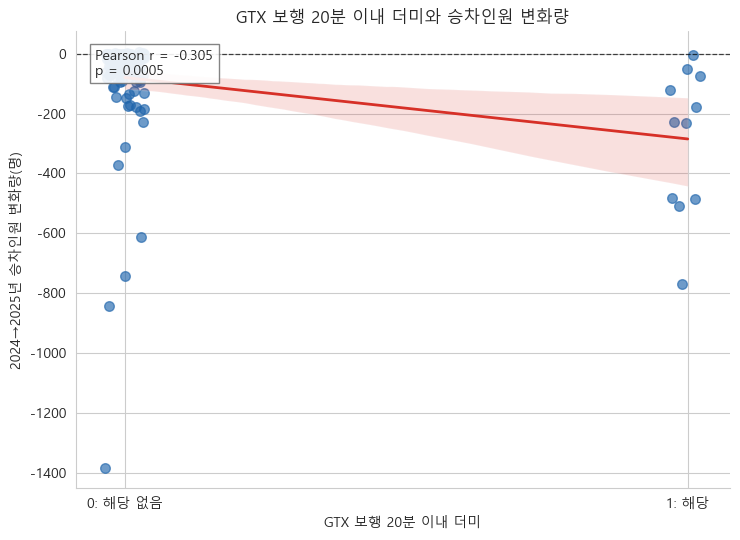

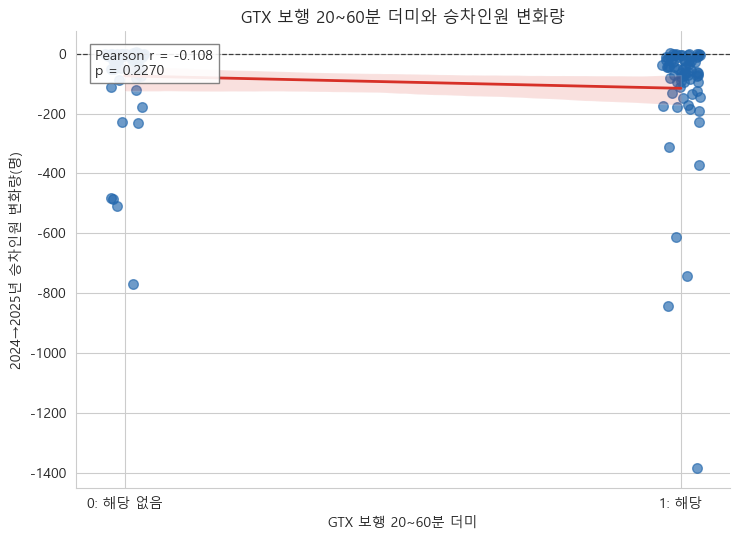

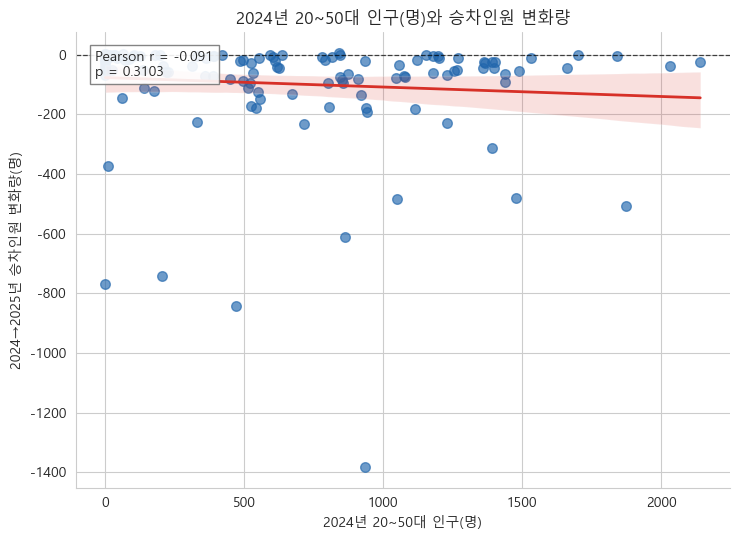

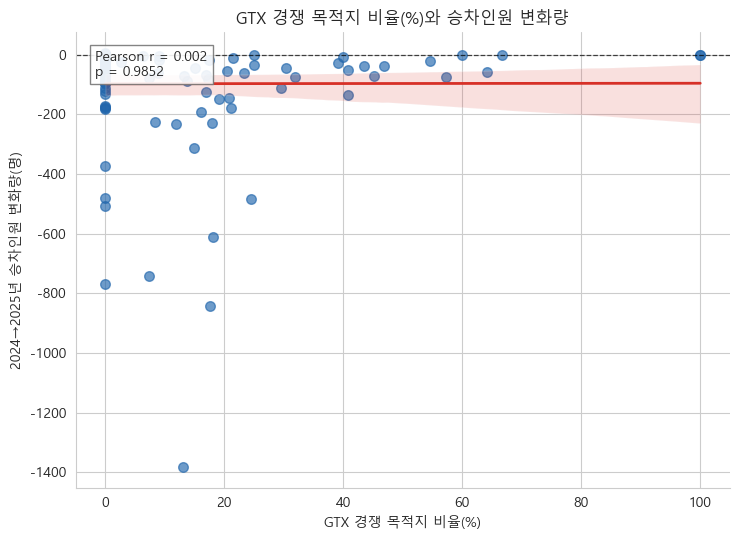

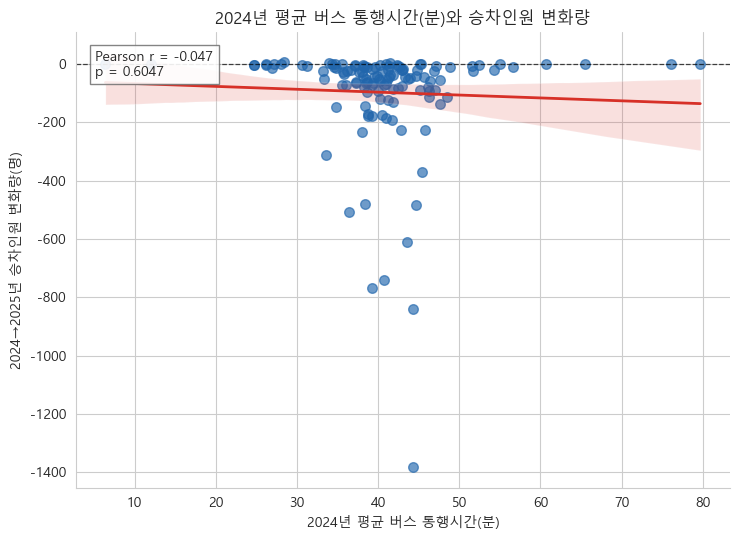

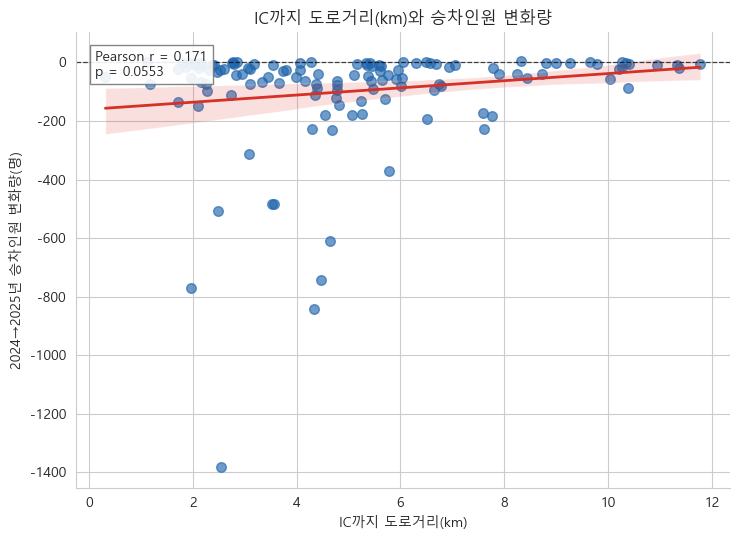

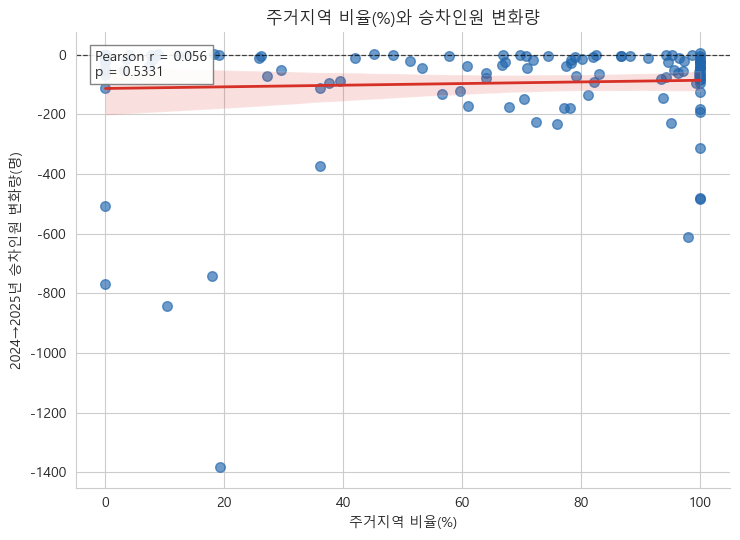

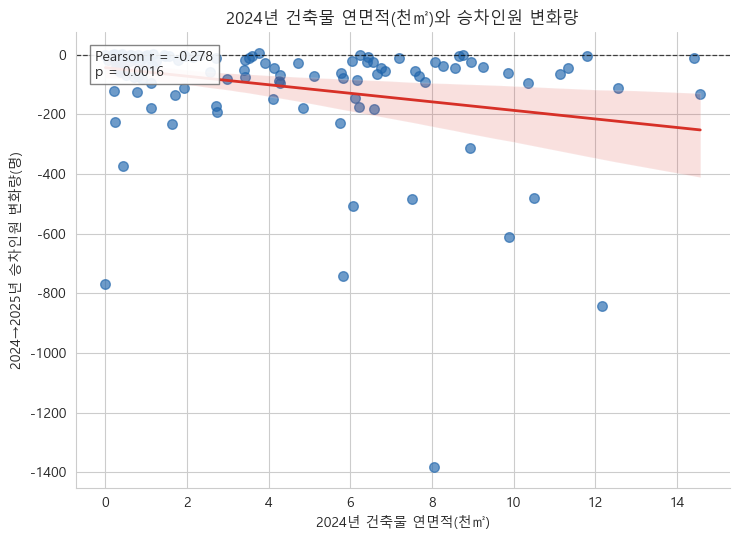

===== 독립변수별 Pearson 상관분석 =====


,독립변수,표본 수,Pearson r,p값,유의성
0,GTX 보행 20분 이내 더미,126,-0.3045,0.0005,***
1,GTX 보행 20~60분 더미,126,-0.1084,0.2270,
2,2024년 20~50대 인구(명),126,-0.0911,0.3103,
3,GTX 경쟁 목적지 비율(%),126,0.0017,0.9852,
4,2024년 평균 버스 통행시간(분),126,-0.0466,0.6047,
5,IC까지 도로거리(km),126,0.1712,0.0553,*
6,주거지역 비율(%),126,0.0560,0.5331,
7,2024년 건축물 연면적(천㎡),126,-0.2785,0.0016,***


In [40]:
# 19. 각 독립변수와 승차인원 변화량의 상관분석
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import seaborn as sns
from scipy.stats import pearsonr
from IPython.display import display

PROJECT_CORR = UROP_ROOT
PROCESSED_CORR = PROJECT_CORR / 'data' / 'processed' / 'gtx_a'

def read_matching_csv(prefix, required_column):
    for csv_path in PROCESSED_CORR.glob(f'{prefix}*.csv'):
        frame = pd.read_csv(csv_path, encoding='utf-8-sig', low_memory=False)
        if required_column in frame.columns:
            return frame
    raise FileNotFoundError(f'{prefix} 파일에서 {required_column} 열을 찾지 못했습니다.')

ID_CORR = '셀 ID'
RESIDENTIAL_CORR = '주거지역 비율(%)'
FLOOR_CORR = '2024년 건축물 연면적(천㎡)'

corr_model = read_matching_csv('18_', 'change_all')
corr_extra = read_matching_csv('18-1_', 'bus_time_mean')
corr_land = read_matching_csv('19_', RESIDENTIAL_CORR)
corr_floor = read_matching_csv('24_', FLOOR_CORR)

for frame in [corr_model, corr_extra, corr_land, corr_floor]:
    frame[ID_CORR] = pd.to_numeric(frame[ID_CORR], errors='coerce').astype('Int64')

corr_model = (
    corr_model
    .merge(corr_extra[[ID_CORR, 'bus_time_mean']], on=ID_CORR, how='left', validate='one_to_one')
    .merge(corr_land[[ID_CORR, RESIDENTIAL_CORR]], on=ID_CORR, how='left', validate='one_to_one')
    .merge(corr_floor[[ID_CORR, FLOOR_CORR]], on=ID_CORR, how='left', validate='one_to_one')
)

CORR_VARIABLES = [
    'walk_20', 'walk_20_60', 'pop_20_50', 'competing_share',
    'bus_time_mean', 'ic_access', RESIDENTIAL_CORR, FLOOR_CORR,
]
CORR_LABELS = {
    'walk_20': 'GTX 보행 20분 이내 더미',
    'walk_20_60': 'GTX 보행 20~60분 더미',
    'pop_20_50': '2024년 20~50대 인구(명)',
    'competing_share': 'GTX 경쟁 목적지 비율(%)',
    'bus_time_mean': '2024년 평균 버스 통행시간(분)',
    'ic_access': 'IC까지 도로거리(km)',
    RESIDENTIAL_CORR: '주거지역 비율(%)',
    FLOOR_CORR: '2024년 건축물 연면적(천㎡)',
}

sns.set_style('whitegrid')
font_path_corr = Path(r'C:\Windows\Fonts\malgun.ttf')
if font_path_corr.exists():
    fm.fontManager.addfont(str(font_path_corr))
    plt.rcParams['font.family'] = fm.FontProperties(fname=str(font_path_corr)).get_name()
plt.rcParams['axes.unicode_minus'] = False

for column in ['change_all'] + CORR_VARIABLES:
    corr_model[column] = pd.to_numeric(corr_model[column], errors='coerce')

correlation_rows = []
for variable in CORR_VARIABLES:
    plot_data = corr_model[[variable, 'change_all']].dropna().copy()
    correlation, p_value = pearsonr(plot_data[variable], plot_data['change_all'])
    correlation_rows.append({
        '독립변수': CORR_LABELS[variable],
        '표본 수': len(plot_data),
        'Pearson r': correlation,
        'p값': p_value,
    })

    fig, ax = plt.subplots(figsize=(7.5, 5.5))
    is_dummy = set(plot_data[variable].dropna().unique()).issubset({0, 1})
    sns.regplot(
        data=plot_data,
        x=variable,
        y='change_all',
        x_jitter=0.035 if is_dummy else None,
        scatter_kws={'s': 48, 'alpha': 0.65, 'color': '#2166ac'},
        line_kws={'color': '#d73027', 'linewidth': 2},
        ci=95,
        ax=ax,
    )
    ax.axhline(0, color='black', linewidth=0.9, linestyle='--', alpha=0.7)
    ax.set_xlabel(CORR_LABELS[variable])
    ax.set_ylabel('2024→2025년 승차인원 변화량(명)')
    ax.set_title(f'{CORR_LABELS[variable]}와 승차인원 변화량')
    ax.text(
        0.03, 0.96,
        f'Pearson r = {correlation:.3f}\np = {p_value:.4f}',
        transform=ax.transAxes, va='top', ha='left', fontsize=10,
        bbox=dict(facecolor='white', edgecolor='#777777', alpha=0.9),
    )
    if is_dummy:
        ax.set_xticks([0, 1])
        ax.set_xticklabels(['0: 해당 없음', '1: 해당'])
    ax.spines[['top', 'right']].set_visible(False)
    plt.tight_layout()
    plt.show()

correlation_table = pd.DataFrame(correlation_rows)
correlation_table['유의성'] = np.select(
    [correlation_table['p값'] < .01, correlation_table['p값'] < .05,
     correlation_table['p값'] < .10],
    ['***', '**', '*'], default=''
)
print('===== 독립변수별 Pearson 상관분석 =====')
display(correlation_table.round(4))
